In [390]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/historicaldata-costco-2col/HistoricalData_Costco_2Col.csv


##                                                                  **Activity1**

#### Description
The aim of this report is to perform a comprehensive time series analysis and forecasting for the Costco stock price dataset. Our primary goal is to predict the future close price with the help of different time series forecasting methods such as Naïve, Average historical, simple average, Exponential Smoothing method different variants (SES, Holts Linear and Holts Winters(Additive and Multiplicative) approaches) including ARIMA, SARIMA and regression-based approaches.
Our workflow involves cleaning and transforming Costco historical data, including numerical values and date handling, after that finding insights like series trend, seasonality and the descriptive statistics. For the performance judgement of different models which are mentioned above, the accuracy metrics of each model is conducted separately. In the last for the comparative analysis and interpretation we have seen which model stood on first rank regarding most effective forecasting for our Costco dataset and we discussed our outcomes.


In [391]:
#Importing libararies

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import statsmodels.api as sm
import math
import warnings
warnings.filterwarnings("ignore")
from pylab import rcParams
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.holtwinters import HoltWintersResults
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import LinearRegression
print("Libraries Imported Successfully")

Libraries Imported Successfully


In [392]:
# we Loaded the dataset and use head key to see top 5 rows to understand the data structure of the dataset.

df = pd.read_csv('/kaggle/input/historicaldata-costco-2col/HistoricalData_Costco_2Col.csv')
df.head()

,Date,Close/Last
0,01-07-26,$882.58
1,01-06-26,$889.10
2,01-05-26,$875.74
3,01-02-26,$854.50
4,12/31/2025,$862.34


In [393]:
# We should rename the column names
df.columns = ['Date','Close']
df.head()

,Date,Close
0,01-07-26,$882.58
1,01-06-26,$889.10
2,01-05-26,$875.74
3,01-02-26,$854.50
4,12/31/2025,$862.34


# Description of problem and Preparation Data



In [394]:
# we are converting the Date column to datetime objects and setting it as the dataframe index for handling the potential errors.
df['Date'] =pd.to_datetime(df['Date'],format="mixed" ) # we used mixed because we got two different formats of dates in column.
df = df.sort_values('Date')
df = df.set_index('Date')

In [395]:
df.head()

,Close
Date,
2021-01-08,$369.94
2021-01-11,$364.01
2021-01-12,$364.20
2021-01-13,$366.95
2021-01-14,$362.35


## Cleaning Data

In [396]:
# Cleaning the Close column by removing the $ sign form the column and convert them into a numeric data type for numerical analysis and forecasting.
df['Close'] = df['Close'].astype(str).str.replace('$','',regex = False).str.replace(',','',regex = False).str.strip().astype(float)

In [397]:
# Sorting the date column of the dataframe index in ascending order
df.sort_index(inplace= True)

In [398]:
# Grouping all the rows ending with the last date of that month and which comes within unique calendar month. Then it takes mean within each month.
monthly_df = df.resample('ME').mean()

In [399]:
# Sorting the date column of the dataframe index in ascending order
monthly_df.sort_index(inplace= True)

In [400]:
print(monthly_df.round(2))

             Close
Date              
2021-01-31  361.55
2021-02-28  351.29
2021-03-31  332.29
2021-04-30  366.94
2021-05-31  381.05
...            ...
2025-09-30  950.49
2025-10-31  928.37
2025-11-30  912.34
2025-12-31  877.67
2026-01-31  875.48

[61 rows x 1 columns]


## Exploratory visualization and Data Analysis


Here we will see the discriptive statistics and its insights of the Close column of the dataset. Like trend, Seasonality, patterns and the shapes of the distribution of the stocks etc

In [401]:
# Non monthly data set statistics
df.describe().round()

,Close
count,1255.0
mean,651.0
std,214.0
min,311.0
25%,488.0
50%,556.0
75%,886.0
max,1077.0


In [402]:
# Let's describe the monthly dataset
monthly_df.describe().round(2)

,Close
count,61.00
mean,653.29
std,215.85
min,332.29
25%,485.58
50%,549.82
75%,877.67
max,1046.39


### Insight of above cell 
As mean-25%=167.71, mean-50%=103.47 and mean-75%=224.38. As mean is closer the median and mean slightly bigger then median implies positive skewness exists in our data but not extremely. Moreover the gap between mean and median means our series is not stationary. The standard deviation 215.85, 33% of the mean indicates data has high month to month variation.

In [403]:
# Checking Skewness
skew_value = monthly_df['Close'].skew()
print("Skewness:", skew_value)
# loop
if skew_value > 0:
    print("Positive skewed")
elif skew_value < 0:
    print("Negative skewed")
else:
    print("Perfectly symmetrical")

Skewness: 0.3884391149566488
Positive skewed


### Lets visualize the trend and seasonality characteristics of the data

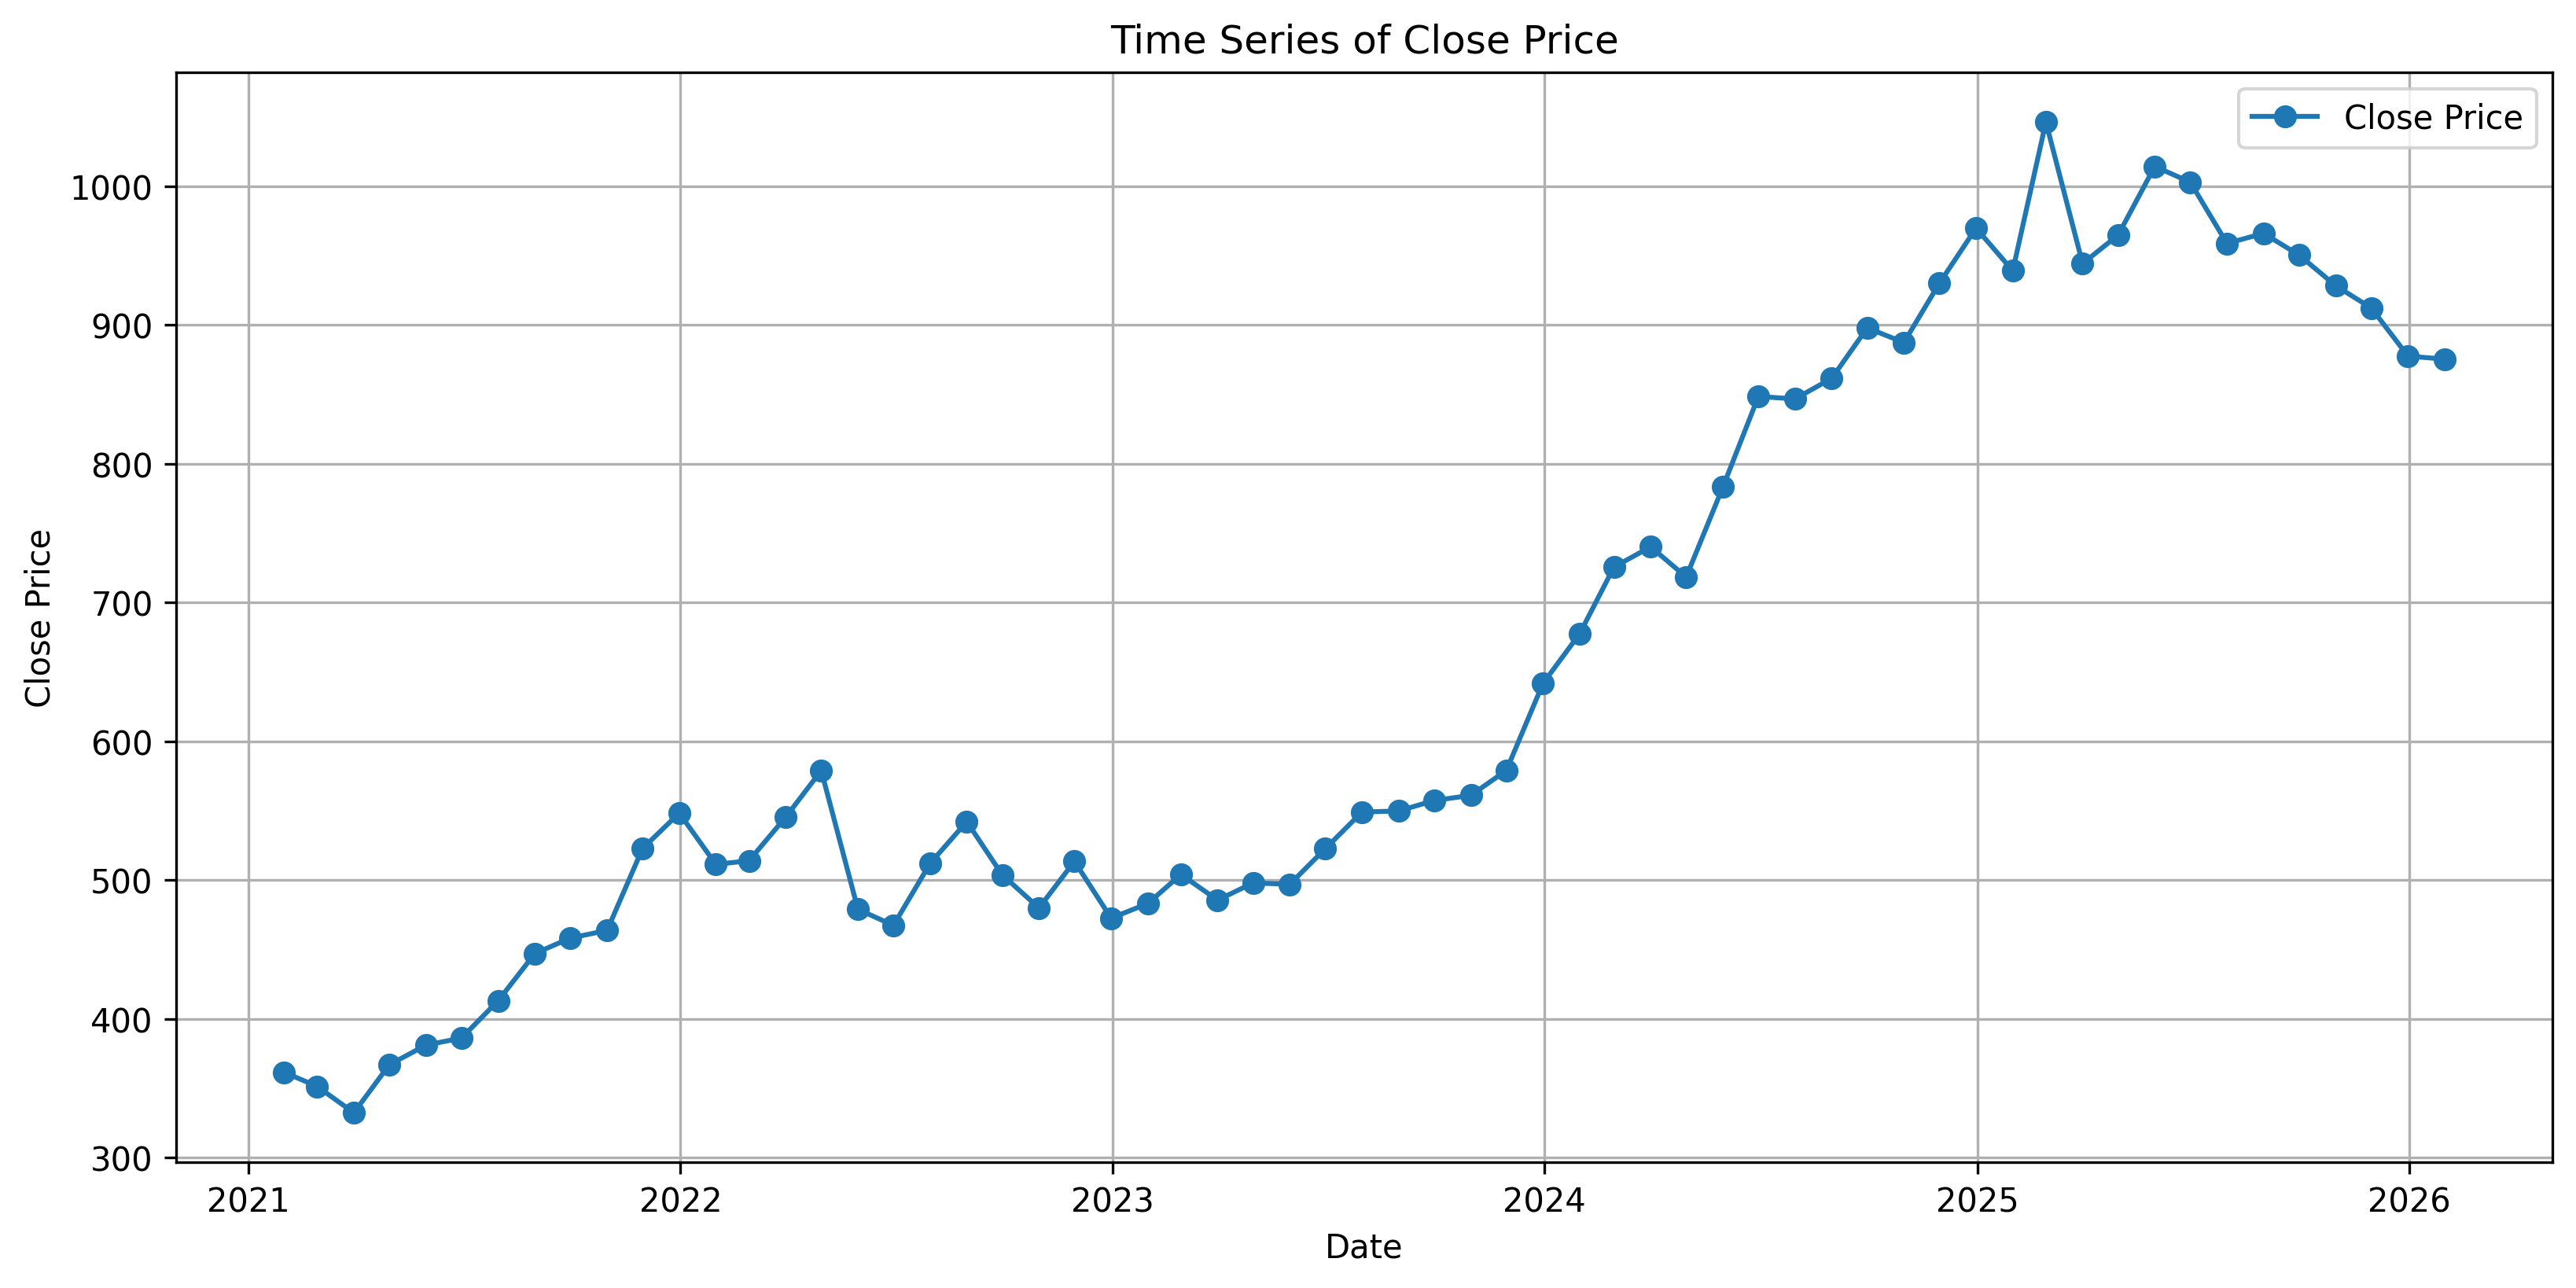

In [404]:
#Lets visualize the trend and seasonality characteristics of the data
plt.figure(figsize = (13,6),dpi= 300)
plt.plot(monthly_df.index, monthly_df['Close'], label = 'Close Price', marker = 'o')
plt.title('Time Series of Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

(b) 
## Decomposition Time Series

In [405]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pylab import rcParams

In [406]:
# Additive Seasonal Decomposition
decomposition_additive = seasonal_decompose(monthly_df['Close'], model = 'additive', period = 12)

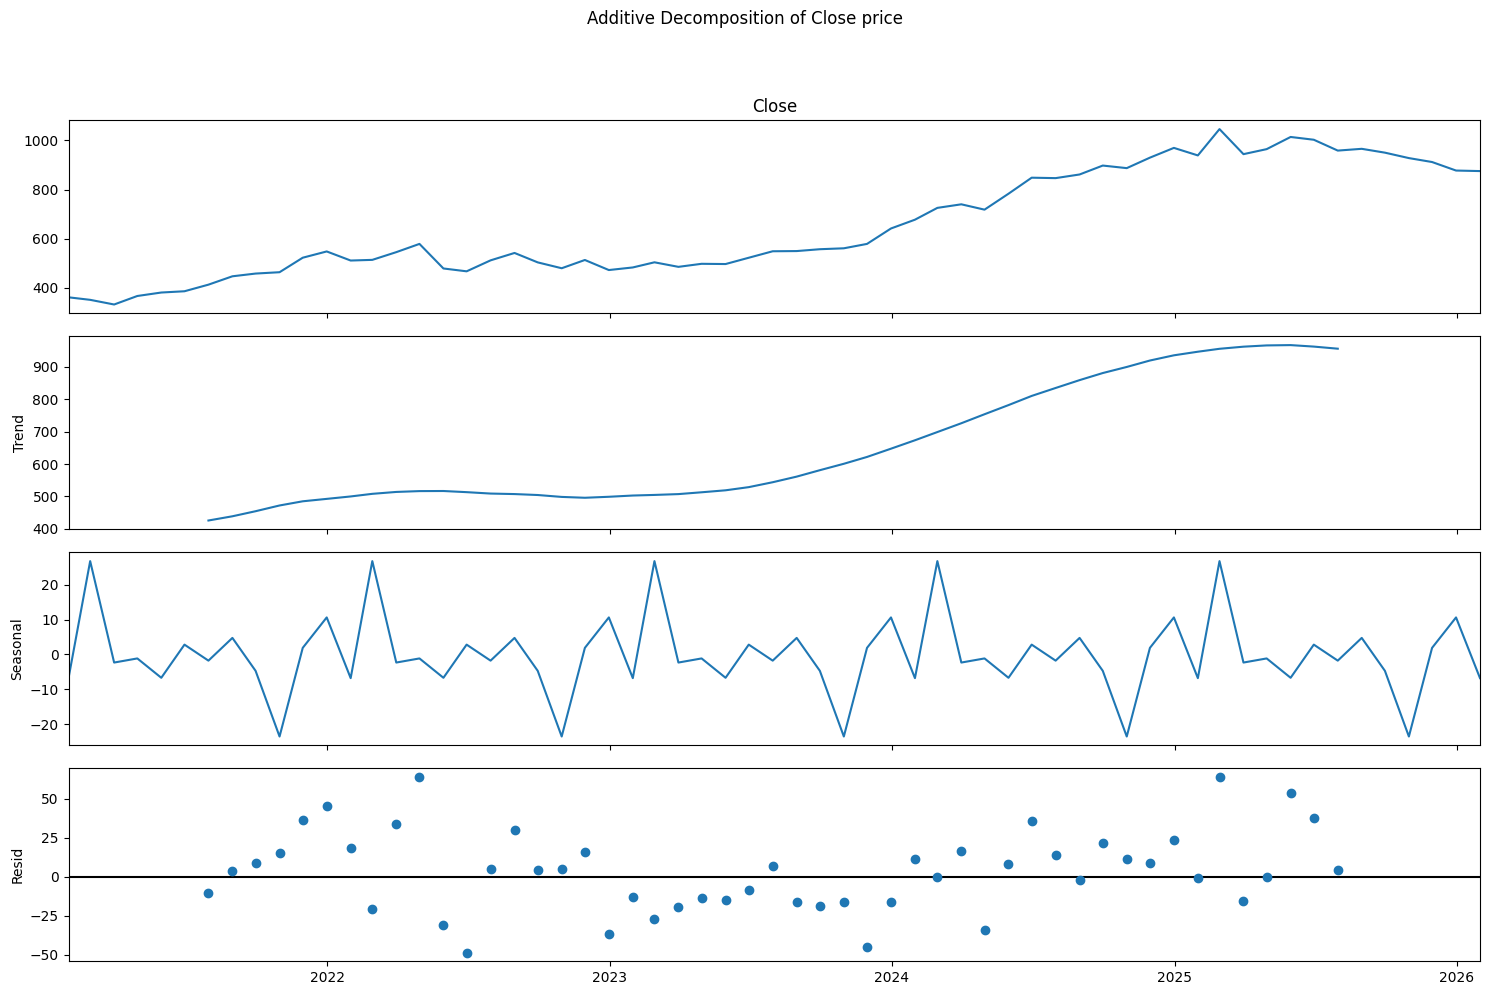

In [407]:
# Let's visualize Additive Decomposition

fig_additive = decomposition_additive.plot()
fig_additive.set_size_inches(15,10)
fig_additive.suptitle('Additive Decomposition of Close price', y = 1.02)
plt.tight_layout(rect=[0,0.03,1,0.98])
plt.show()

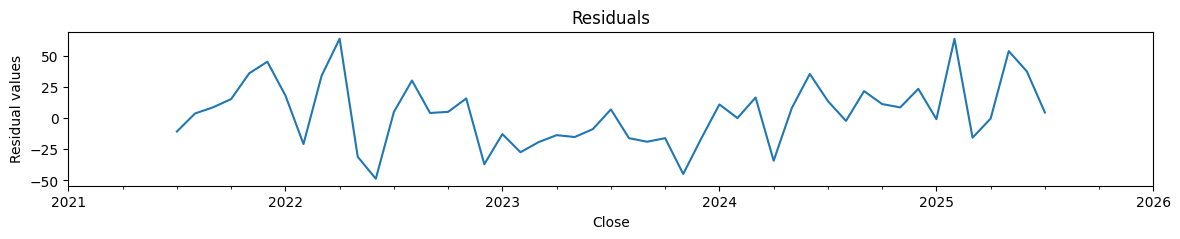

In [408]:
# zooming in noise component in time series
fig_decomp_resid = decomposition_additive.resid
ax = fig_decomp_resid.plot(figsize=(14, 2))
ax.set_xlabel('Close')
ax.set_ylabel('Residual values')
ax.set_title('Residuals')
plt.show()

Graph shows gradual increase in the trend in [2021-2022], kept approximately stable during [2022-2023] and after that increases and ramped up sharply from the mid 2023 till 2025. Seasonality keep oscillating between ±20, while trend shows range in hundreds interval which implies that seasonality exists but trend impact more as compared to the seasonality. The spike of the residual lies within ±50. Outliers in figure tells that shocks happened like events, festivals and by news etc.

In [409]:
decomposition_multiplicative = seasonal_decompose(monthly_df['Close'], model = 'multiplicative', period = 12)

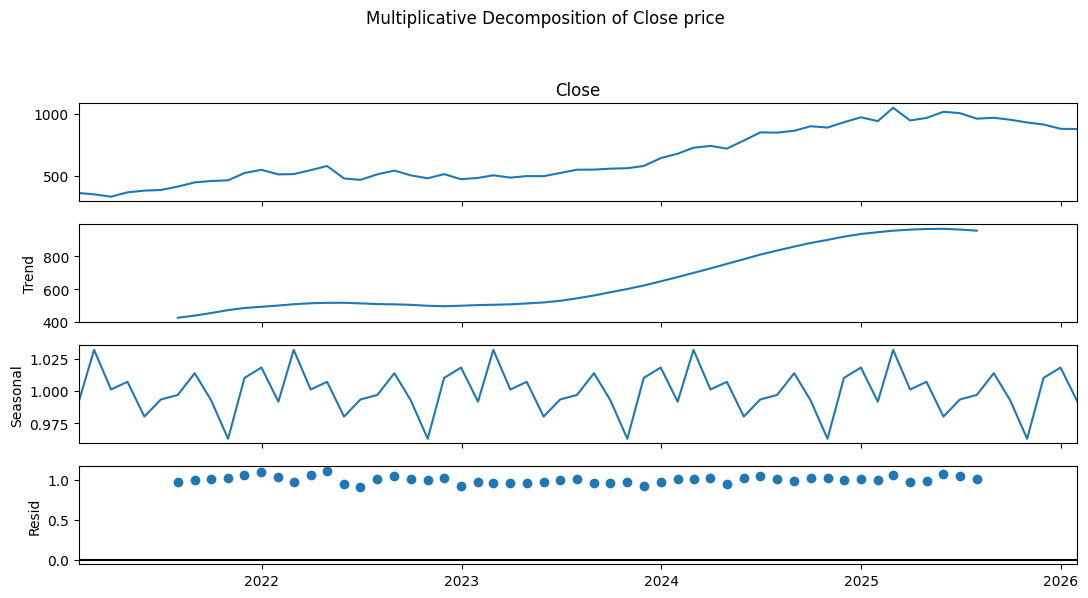

In [410]:
# lets visualize decomposition_multiplicative model

fig_multiplicative = decomposition_multiplicative.plot()
fig_multiplicative.set_size_inches(11,6)
fig_multiplicative.suptitle('Multiplicative Decomposition of Close price', y = 1.02)
plt.tight_layout(rect=[0,0.03,1,0.98])
plt.show()

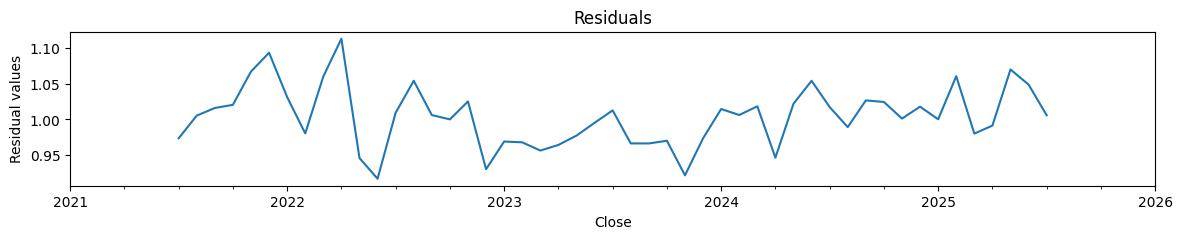

In [411]:
#For deep analysis for Noise component in multiplicative decomposition of the time series
fig_decomp_resid = decomposition_multiplicative.resid
ax = fig_decomp_resid.plot(figsize=(14, 2))
ax.set_xlabel('Close')
ax.set_ylabel('Residual values')
ax.set_title('Residuals')
plt.show()

As we can see the multiplicative decomposition gave us more realistic as compared to the previous additive decomposition. The trend looks quite similar. In seasonality the multiplicative decomposition oscillate between [0.975 - 1.025], means the effect of seasonality is ±2.5%. In additive model close price change with fix figure ±20, which seems not practical for our case. As our residual looks closer to 1, fluctuate between 0.95 to 1.05 (further details in notebook) which implies multiplicative decomposition is better then the additive decomposition.

## Time Series Forecasting

In [412]:
forecast_horizon=12
print(forecast_horizon)

12


Now we will divide the Close data into training and testing sets. I splited the data in the ratio of 81% and 19% respectively.

In [413]:
train_data = monthly_df[:-forecast_horizon]

test_data = monthly_df[-forecast_horizon:]

In [414]:
print(train_data)

                 Close
Date                  
2021-01-31  361.548000
2021-02-28  351.288421
2021-03-31  332.294783
2021-04-30  366.937619
2021-05-31  381.047500
2021-06-30  386.197727
2021-07-31  413.084286
2021-08-31  447.114091
2021-09-30  458.248571
2021-10-31  463.739048
2021-11-30  522.780952
2021-12-31  548.298182
2022-01-31  511.288500
2022-02-28  514.016316
2022-03-31  545.445652
2022-04-30  578.978500
2022-05-31  478.951905
2022-06-30  467.364762
2022-07-31  512.025500
2022-08-31  542.148261
2022-09-30  503.754762
2022-10-31  479.915714
2022-11-30  513.519048
2022-12-31  472.560476
2023-01-31  483.124500
2023-02-28  504.068947
2023-03-31  485.580000
2023-04-30  497.970000
2023-05-31  497.001818
2023-06-30  522.661905
2023-07-31  549.049000
2023-08-31  549.824783
2023-09-30  557.360500
2023-10-31  561.102273
2023-11-30  579.005238
2023-12-31  641.807000
2024-01-31  677.577619
2024-02-29  725.677000
2024-03-31  740.207000
2024-04-30  718.453182
2024-05-31  783.259545
2024-06-30 

In [415]:
print(test_data)

                  Close
Date                   
2025-02-28  1046.391579
2025-03-31   944.406190
2025-04-30   964.835238
2025-05-31  1014.363810
2025-06-30  1003.061500
2025-07-31   958.914545
2025-08-31   966.118571
2025-09-30   950.485714
2025-10-31   928.368696
2025-11-30   912.341053
2025-12-31   877.670455
2026-01-31   875.480000


In [416]:
# Let's check length of training and test data
print("Train:", len(train_data), "Test:", len(test_data))

Train: 49 Test: 12


### Naive Method

In this forecasting usually we forecast for all the points in the test data set simply are the last output value from the training data set. Let's calculate it.

In [417]:
naive_forecast = pd.Series([train_data.iloc[-1]] * forecast_horizon, index=test_data.index)# getting last training value

In [418]:
print(naive_forecast)

Date
2025-02-28    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-03-31    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-04-30    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-05-31    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-06-30    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-07-31    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-08-31    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-09-30    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-10-31    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-11-30    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2025-12-31    Close    939.2125
Name: 2025-01-31 00:00:00, d...
2026-01-31    Close    939.2125
Name: 2025-01-31 00:00:00, d...
Freq: ME, dtype: object


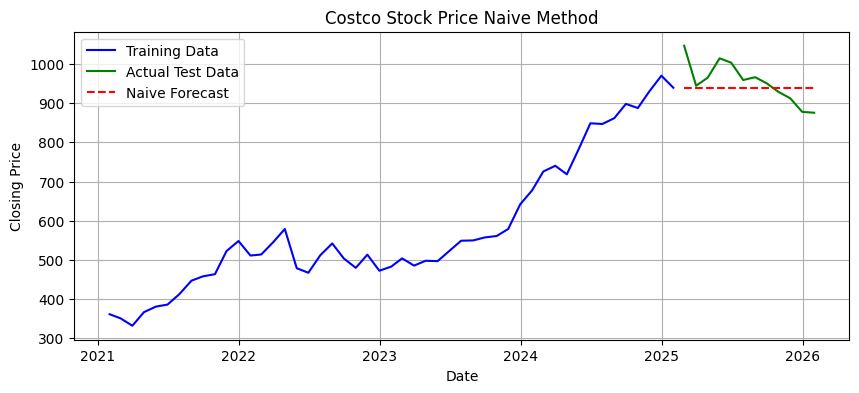

In [419]:
plt.figure(figsize=(10,4))
plt.plot(train_data, label='Training Data', color='blue')
plt.plot(test_data, label='Actual Test Data', color='green')
plt.plot(naive_forecast, label='Naive Forecast', color='red', linestyle='--')
plt.title('Costco Stock Price Naive Method')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

In [420]:
# Naive Method Metrics
rmse_naive = np.sqrt(mean_squared_error(test_data['Close'], naive_forecast)).round(2)
mape_naive = np.round(np.mean(np.abs(test_data['Close'] - naive_forecast) / test_data['Close']) * 100, 2)
mae_naive = np.round(np.mean(np.abs(test_data['Close'] - naive_forecast)), 2)

results = pd.DataFrame({'Method':['Naive Method'], 'MAPE': [mape_naive], 'RMSE': [rmse_naive], 'MAE': [mae_naive]})
naive1 = results[['Method', 'RMSE', 'MAE', 'MAPE']]
naive1

,Method,RMSE,MAE,MAPE
0,Naive Method,51.5,41.49,4.3


An other approch of naive method to check the results

In [421]:
def naive_method(data, nforecast):
    """
    Forecast using the Naive Method.
    
    Parameters:
        data (list): A list of historical data points.
        nforecast: number of forecasts you want to make
        
    Returns:
        forecast (list): A list of forecasts for each period.
    """
    forecast = [data[-1]]  # Initial forecast is the last observed point
    number = nforecast-1 # You can adjust the number of forecast you want to make.
    
    # To forecast the next 24 points, a loop is necessary:
    for i in range(number):
         forecast.append(forecast[-i])
    
    return forecast

In [422]:
y_hat_naive = test_data.copy()
y_hat_naive['naive_forecast'] = naive_method(train_data['Close'], nforecast = 12)

In [423]:
y_hat_naive

,Close,naive_forecast
Date,,
2025-02-28,1046.391579,939.2125
2025-03-31,944.406190,939.2125
2025-04-30,964.835238,939.2125
2025-05-31,1014.363810,939.2125
2025-06-30,1003.061500,939.2125
2025-07-31,958.914545,939.2125
2025-08-31,966.118571,939.2125
2025-09-30,950.485714,939.2125
2025-10-31,928.368696,939.2125


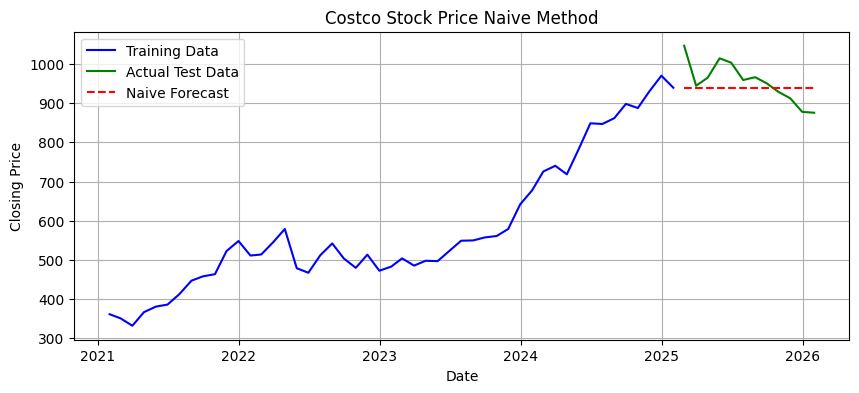

In [424]:
plt.figure(figsize=(10,4))
plt.plot(train_data, label='Training Data', color='blue')
plt.plot(test_data, label='Actual Test Data', color='green')
plt.plot(naive_forecast, label='Naive Forecast', color='red', linestyle='--')
plt.title('Costco Stock Price Naive Method')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

In [425]:
# Naive Method Metrics
rmse_naive = np.sqrt(mean_squared_error(test_data['Close'], y_hat_naive['naive_forecast'])).round(2)
mape_naive = np.round(np.mean(np.abs(test_data['Close'] - y_hat_naive['naive_forecast']) / test_data['Close']) * 100, 2)
mae_naive = np.round(np.mean(np.abs(test_data['Close'] - y_hat_naive['naive_forecast'])), 2)

results = pd.DataFrame({'Method':['Naive Method'], 'MAPE': [mape_naive], 'RMSE': [rmse_naive], 'MAE': [mae_naive]})
naive = results[['Method', 'RMSE', 'MAE', 'MAPE']]
naive

,Method,RMSE,MAE,MAPE
0,Naive Method,51.5,41.49,4.3


As MAE = 41.49, implies our prediction will be 41 points from the actual closing price. 
Mathematically,
Percentage of Mean and Median is 6.36% and 7.55% respectively. It means that Naïve misses 6 to 8 percent. Similarly, for RMSE the Percentage of Mean and Median is 7.88% and 9.37% respectively. It means the error typically ranges from 8 to 9 percent, and the standard deviation = 215.85 having 23.9% tells our series naturally implies that Naïve errors are smaller than overall spread. It means for short term persistence its performance is good.


### Simple Moving Average

Now we will impliment the moving average method where our forecast is for all the points in the test set is the mean of the training set. Moreover the forecast will be kept in a new series with the index of test data.

In [426]:
train_data

,Close
Date,
2021-01-31,361.548000
2021-02-28,351.288421
2021-03-31,332.294783
2021-04-30,366.937619
2021-05-31,381.047500
2021-06-30,386.197727
2021-07-31,413.084286
2021-08-31,447.114091
2021-09-30,458.248571


In [427]:
y_hat_sma = test_data.copy()
sma_interval=12
y_hat_sma['moving_avg_forecast']= train_data['Close'].rolling(sma_interval).mean().iloc[-1]

# This do mean of whole previous data
#mean_train_value = train_data.mean()
#simple_average_forecast = pd.Series(mean_train_value, index = test_data.index)

#simple_average_forecast.head()

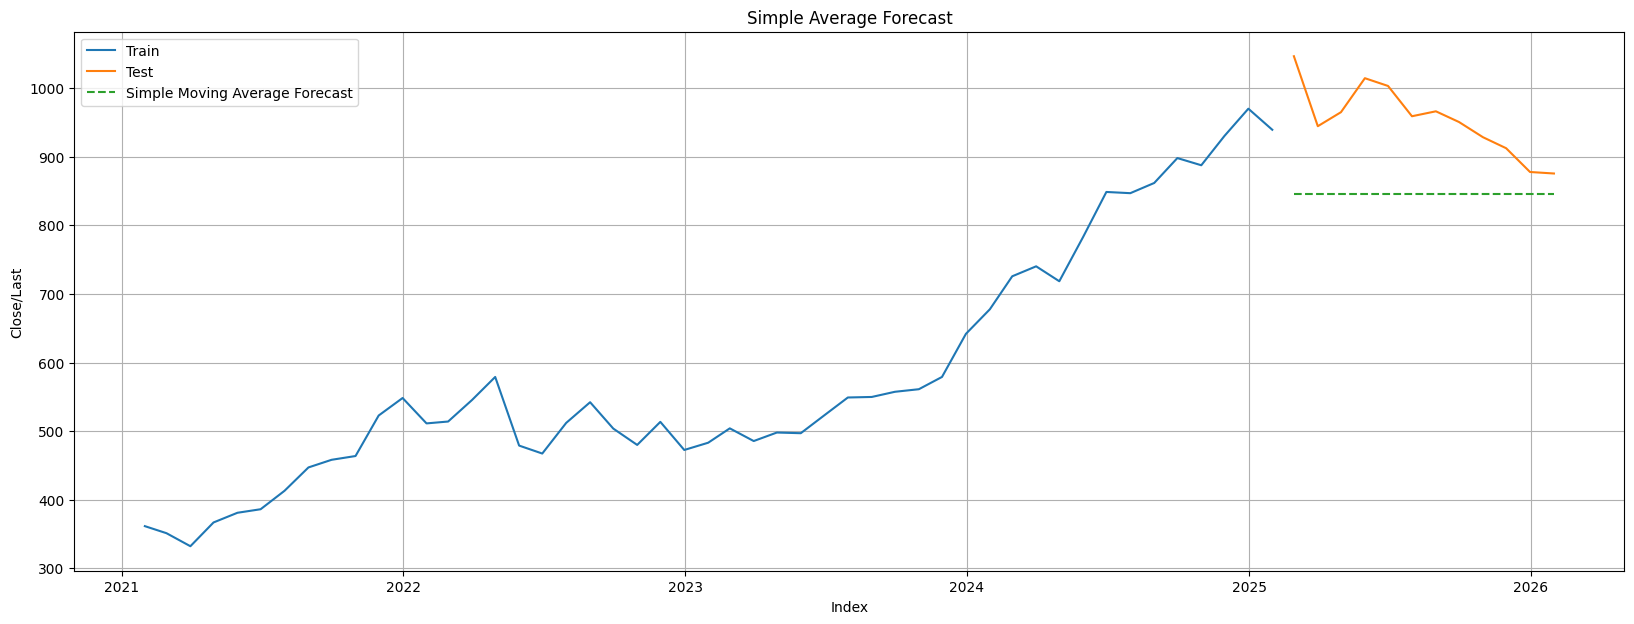

In [428]:
#Plotting
plt.figure(figsize=(20,7))
plt.grid(True)
plt.plot(train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_sma['moving_avg_forecast'], label='Simple Moving Average Forecast', linestyle = "--")
plt.legend(loc='best')
plt.title('Simple Average Forecast')
plt.xlabel('Index')
plt.ylabel('Close/Last')
#plt.tight_layout()
plt.show()

## Accuracy Metrics

In [429]:
from sklearn.metrics import mean_squared_error
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_sma['moving_avg_forecast'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_sma['moving_avg_forecast'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_sma['moving_avg_forecast'])),2)

results = pd.DataFrame({'Method':['Simple Moving Averages method'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
sma = results[['Method', 'RMSE', 'MAE', 'MAPE']]
sma

,Method,RMSE,MAE,MAPE
0,Simple Moving Averages method,118.56,107.75,11.06


The graph and accuracy metrics tells us that this method is not suitable for our data forecast because MAPE is 39.04% means our forecast is about 39.04% away from the actual closing price which is not good forecast

## Simple Average Method ok

In [430]:
# Simple Average Method
mean_train_value = train_data['Close'].mean()
y_hat_simple_avg = test_data.copy()# creating copy of test dataset because we do not want make changes in main dataset
y_hat_simple_avg['simple_average_forecast'] = mean_train_value
y_hat_simple_avg['simple_average_forecast']

Date
2025-02-28    579.7571
2025-03-31    579.7571
2025-04-30    579.7571
2025-05-31    579.7571
2025-06-30    579.7571
2025-07-31    579.7571
2025-08-31    579.7571
2025-09-30    579.7571
2025-10-31    579.7571
2025-11-30    579.7571
2025-12-31    579.7571
2026-01-31    579.7571
Freq: ME, Name: simple_average_forecast, dtype: float64

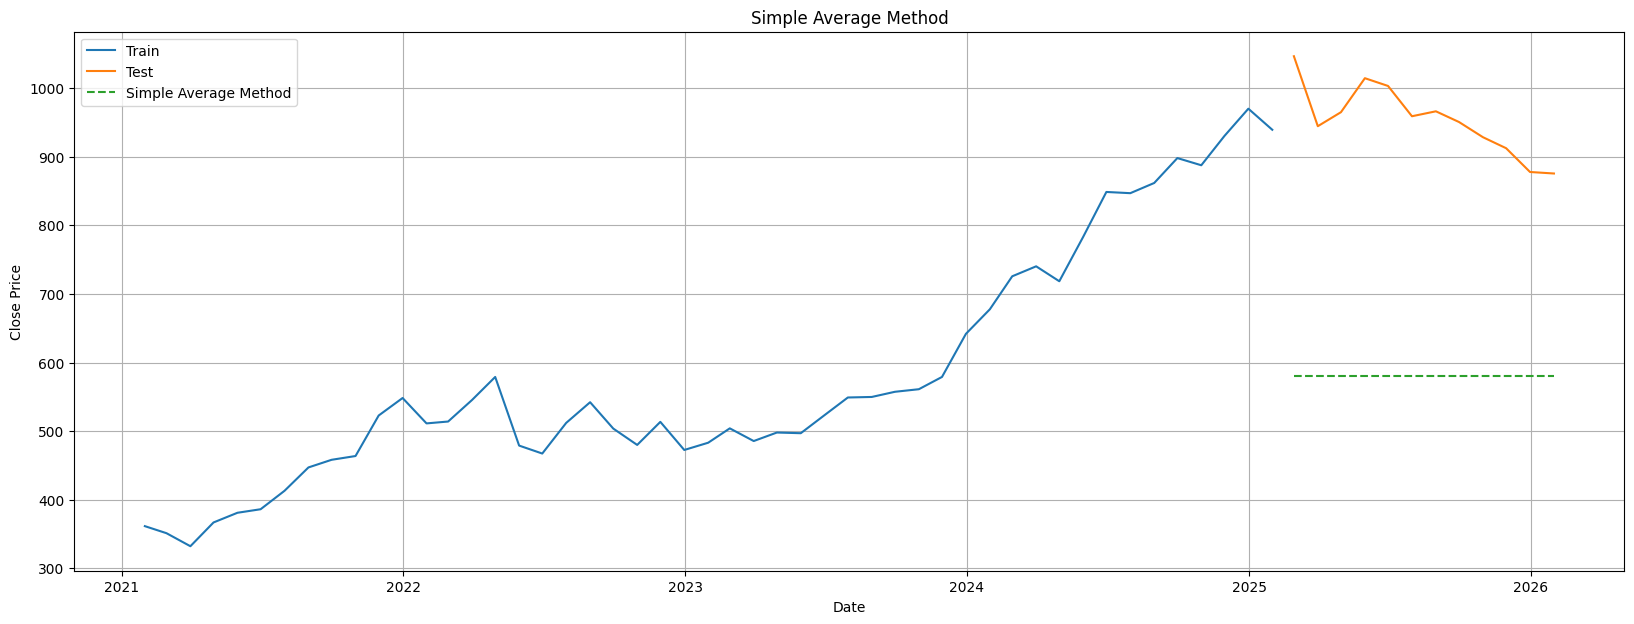

In [431]:
# Visualization of Simple Average Method
plt.figure(figsize=(20,7))
plt.grid(True)
plt.plot(train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_simple_avg['simple_average_forecast'], label='Simple Average Method', linestyle = "--")
plt.legend(loc='best')
plt.title('Simple Average Method')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

In [432]:
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_simple_avg['simple_average_forecast'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_simple_avg['simple_average_forecast'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_simple_avg['simple_average_forecast'])),2)

results_simple_avg = pd.DataFrame({'Method':['Simple Average Method'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
results_simple_avg = results_simple_avg[['Method', 'RMSE', 'MAE', 'MAPE']]
results_simple_avg

,Method,RMSE,MAE,MAPE
0,Simple Average Method,377.04,373.78,39.04


## Average Historical Method ok

In [433]:
# Average Historical Method
train_data_copy = train_data.copy()
train_data_copy['Month'] = train_data_copy.index.month
monthly_avg_train = train_data_copy.groupby('Month')['Close'].mean()
y_hat_avg_hist = test_data.copy()
y_hat_avg_hist['average_historical_forecast'] = test_data.index.month.map(monthly_avg_train)
y_hat_avg_hist['average_historical_forecast']

Date
2025-02-28    523.762671
2025-03-31    525.881859
2025-04-30    540.584825
2025-05-31    535.065192
2025-06-30    556.199783
2025-07-31    580.239924
2025-08-31    600.187579
2025-09-30    604.334208
2025-10-31    598.062628
2025-11-30    636.372560
2025-12-31    658.145462
2026-01-31    594.550224
Freq: ME, Name: average_historical_forecast, dtype: float64

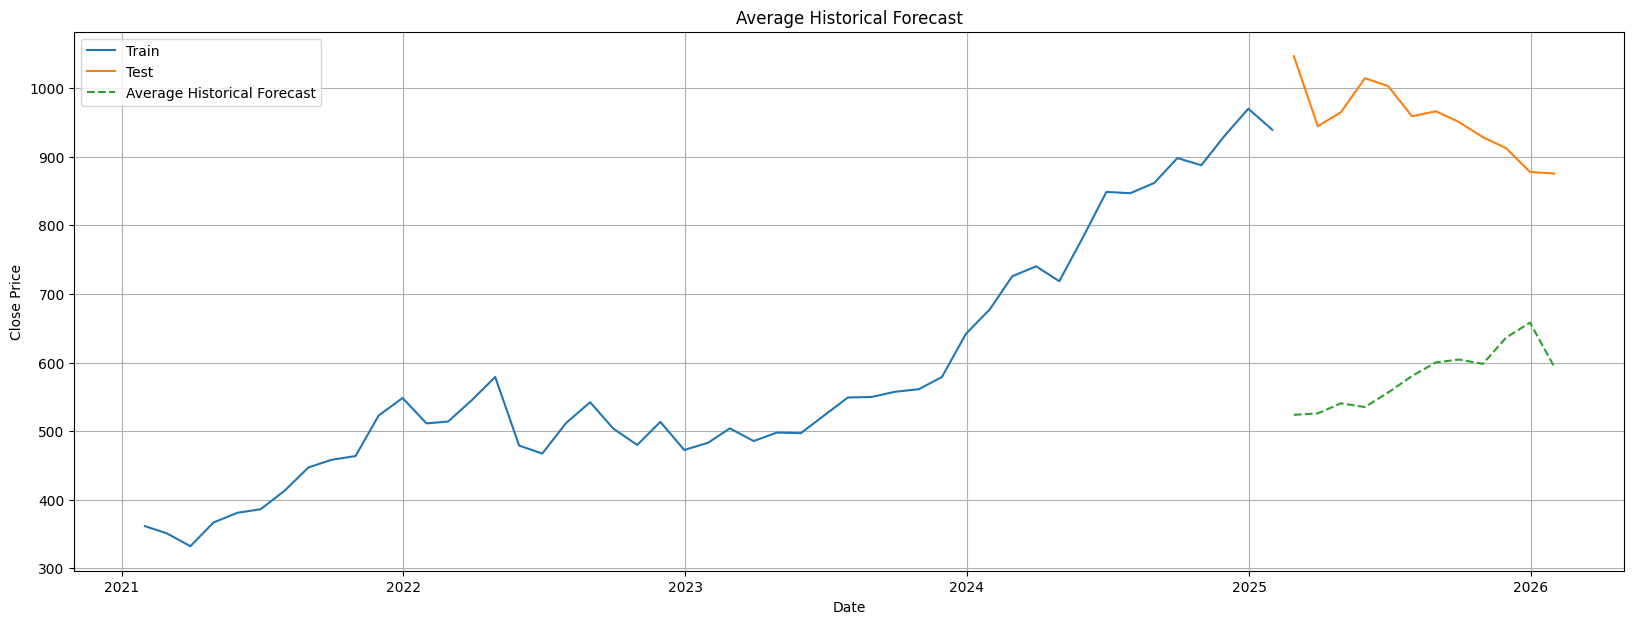

In [434]:
#Plotting
plt.figure(figsize=(20,7))
plt.grid(True)
plt.plot(train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_avg_hist['average_historical_forecast'], label='Average Historical Forecast', linestyle = "--")
plt.legend(loc='best')
plt.title('Average Historical Forecast')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

## Accuracy Metrics

In [435]:
#Accuracy Metric of Average Historical Method
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_avg_hist['average_historical_forecast'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg_hist['average_historical_forecast'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg_hist['average_historical_forecast'])),2)

results_avg_historical = pd.DataFrame({'Method':['Average Historical Method'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
results_avg_historical = results_avg_historical[['Method', 'RMSE', 'MAE', 'MAPE']]
print(results_avg_historical)

                      Method    RMSE     MAE  MAPE
0  Average Historical Method  383.75  374.09  38.9


## Exponential Smoothing Methods

### Simple Exponential Smoothing(SES)

This method includes the fitting of exponential smoothing for training set with no season and trend and then fit to optimize the smoothing parameter and predict the prediction for the set forecast horizon which is 12 in our case.

In [436]:
# storing forecasts copying test data because we want do not want changes in main data
y_hat_avg = test_data.copy()

# List of all possible alpha values for testing
alpha_values = [0.1,0.2,0.3,0.4,0.5,0.6, 0.7,0.8,0.9]

# This Loop tells for each value of alpha, see their forecasts
for a in alpha_values:
    model = SimpleExpSmoothing(np.asarray(train_data['Close'])).fit(
        smoothing_level=a, 
        optimized=False)
    # Creating the column name
    col_name = f"SES_{a}"
    # Storing forecast in test dataframe
    y_hat_avg[col_name] = model.forecast(len(test_data))
y_hat_avg.head()

,Close,SES_0.1,SES_0.2,SES_0.3,SES_0.4,SES_0.5,SES_0.6,SES_0.7,SES_0.8,SES_0.9
Date,,,,,,,,,,
2025-02-28,1046.391579,780.961739,877.14513,913.744837,930.115655,938.208785,942.183861,943.675841,943.426479,941.843535
2025-03-31,944.406190,780.961739,877.14513,913.744837,930.115655,938.208785,942.183861,943.675841,943.426479,941.843535
2025-04-30,964.835238,780.961739,877.14513,913.744837,930.115655,938.208785,942.183861,943.675841,943.426479,941.843535
2025-05-31,1014.363810,780.961739,877.14513,913.744837,930.115655,938.208785,942.183861,943.675841,943.426479,941.843535
2025-06-30,1003.061500,780.961739,877.14513,913.744837,930.115655,938.208785,942.183861,943.675841,943.426479,941.843535


In [437]:
# comparing the errors for each value of alpha
errors = {}
for a in alpha_values:
    col = f"SES_{a}"
    mae = mean_absolute_error(test_data['Close'], y_hat_avg[col])
    rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_avg[col]))
    mape = np.mean(np.abs((test_data['Close']-y_hat_avg[col])/test_data['Close']))*100
    
    errors[a] = {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}
errors

{0.1: {'MAE': 172.57470697332425,
  'RMSE': np.float64(179.5238209044131),
  'MAPE': np.float64(17.877809083693638)},
 0.2: {'MAE': 76.66883744730615,
  'RMSE': np.float64(91.00772443934876),
  'MAPE': np.float64(7.795324341448319)},
 0.3: {'MAE': 52.415442773955455,
  'RMSE': np.float64(63.48342230125852),
  'MAPE': np.float64(5.354114498370115)},
 0.4: {'MAE': 44.521193890397136,
  'RMSE': np.float64(54.72939107796787),
  'MAPE': np.float64(4.585593276895907)},
 0.5: {'MAE': 41.82348384164724,
  'RMSE': np.float64(51.785229360989554),
  'MAPE': np.float64(4.3354531996721155)},
 0.6: {'MAE': 40.49845839353312,
  'RMSE': np.float64(50.750901133011425),
  'MAPE': np.float64(4.212592713583796)},
 0.7: {'MAE': 40.00113185992287,
  'RMSE': np.float64(50.43812366850483),
  'MAPE': np.float64(4.166479048558767)},
 0.8: {'MAE': 40.08425237524576,
  'RMSE': np.float64(50.48746588878177),
  'MAPE': np.float64(4.174186241602506)},
 0.9: {'MAE': 40.611900423772646,
  'RMSE': np.float64(50.8281118

In [438]:
#Simple Exponential Smoothing Method
"""
We analyzed that in the previous cell all the possible values of alpha and see their MAE and RMSE.
After analyzing, I fixed the alpha value 0.7 because it gives low value of MAE and RMSE.
"""
alpha = 0.7
y_hat_avg = test_data.copy()
fitting = SimpleExpSmoothing(np.asarray(train_data['Close'])).fit(smoothing_level=alpha, optimized=False)
y_hat_avg['SES'] = fitting.forecast(len(test_data)) # number of forecasting equal to the test size
y_hat_avg['SES']

Date
2025-02-28    943.675841
2025-03-31    943.675841
2025-04-30    943.675841
2025-05-31    943.675841
2025-06-30    943.675841
2025-07-31    943.675841
2025-08-31    943.675841
2025-09-30    943.675841
2025-10-31    943.675841
2025-11-30    943.675841
2025-12-31    943.675841
2026-01-31    943.675841
Freq: ME, Name: SES, dtype: float64

## Visualization

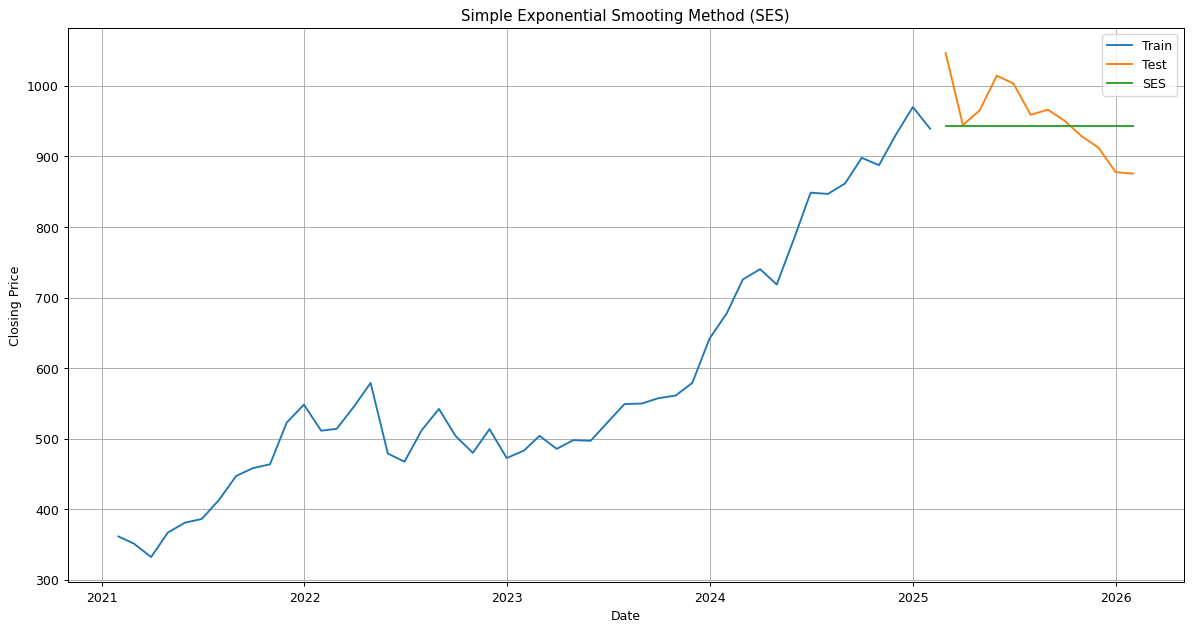

In [439]:
# Visualization
plt.figure(figsize=(16,8),dpi=90)
plt.plot(train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_avg['SES'], label='SES')
plt.legend(loc='best')
plt.title('Simple Exponential Smooting Method (SES)')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid()
plt.show()

## Accuracy Metrics

In [440]:
#Accuracy Metrics
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_avg['SES'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg['SES'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg['SES'])),2)

results = pd.DataFrame({'Method':['Simple Exponential Smoothing'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
ses = results[['Method', 'RMSE', 'MAE', 'MAPE']]
ses

,Method,RMSE,MAE,MAPE
0,Simple Exponential Smoothing,50.44,40.0,4.17


### Holt’s Linear Trend method

In [441]:
# First we will check which is the best value of beta for alpha = 0.7
alpha = 0.7  # our optimized alpha
beta_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
results_hl = {}
for b in beta_values:
    model = Holt(train_data['Close']).fit(
        smoothing_level=alpha,
        smoothing_trend=b,
        optimized=False)
    forecast = model.forecast(len(test_data))
    #for MAE matric
    mae = mean_absolute_error(test_data['Close'], forecast)
    #for RMSE matric
    rmse = np.sqrt(mean_absolute_error(test_data['Close'], forecast))
    #for MAPE matric
    mape = np.mean(np.abs((test_data['Close'] - forecast)/test_data['Close']))*100
    results_hl[b] = {'MAE' : mae, 'RMSE': rmse, 'MAPE': mape}
results_hl

{0.1: {'MAE': 137.02128859693138,
  'RMSE': np.float64(11.705609279184548),
  'MAPE': np.float64(14.86495897485097)},
 0.2: {'MAE': 135.01503474181203,
  'RMSE': np.float64(11.619597012883538),
  'MAPE': np.float64(14.647537388330637)},
 0.3: {'MAE': 116.00688135868876,
  'RMSE': np.float64(10.770649068588613),
  'MAPE': np.float64(12.596318213474555)},
 0.4: {'MAE': 100.26524400253682,
  'RMSE': np.float64(10.013253417473106),
  'MAPE': np.float64(10.885651823506608)},
 0.5: {'MAE': 87.25602939607741,
  'RMSE': np.float64(9.341093586731557),
  'MAPE': np.float64(9.467549502410717)},
 0.6: {'MAE': 75.72465952348597,
  'RMSE': np.float64(8.701991698656462),
  'MAPE': np.float64(8.202271847099638)},
 0.7: {'MAE': 64.42865710220956,
  'RMSE': np.float64(8.026746358407593),
  'MAPE': np.float64(6.9533855477979145)},
 0.8: {'MAE': 51.554360949413784,
  'RMSE': np.float64(7.180136555067305),
  'MAPE': np.float64(5.530028999049649)},
 0.9: {'MAE': 38.8553245671593,
  'RMSE': np.float64(6.2334

### Result
for alpha = 0.7 beta will be 0.9 because the MAE, RMSE and MAPE values are lower then the other values for beta.

In [442]:
#Holt’s Linear Trend Method
y_hat_avg = test_data.copy()
fitting1 = Holt(np.asarray(train_data['Close'])).fit(smoothing_level = 0.7,smoothing_trend = 0.9, optimized = False)
y_hat_avg['Holt_linear'] = fitting1.forecast(len(test_data))
y_hat_avg['Holt_linear'].round(2)

Date
2025-02-28    957.96
2025-03-31    958.01
2025-04-30    958.06
2025-05-31    958.12
2025-06-30    958.17
2025-07-31    958.22
2025-08-31    958.27
2025-09-30    958.32
2025-10-31    958.37
2025-11-30    958.42
2025-12-31    958.47
2026-01-31    958.52
Freq: ME, Name: Holt_linear, dtype: float64

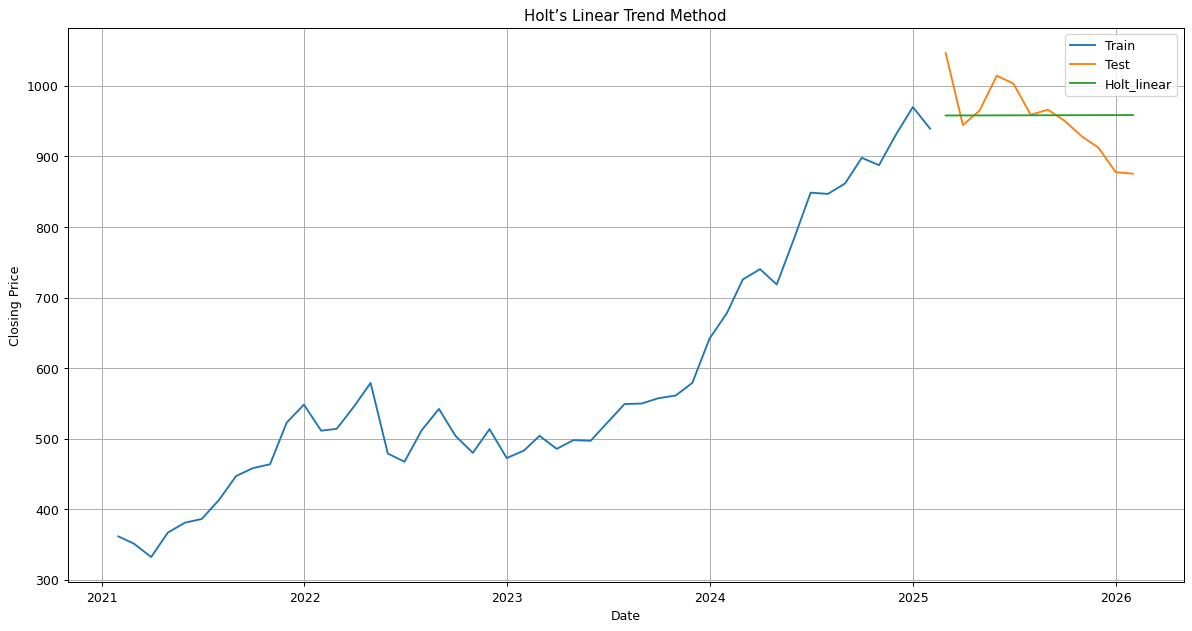

In [443]:
#plotting
plt.figure(figsize=(16,8), dpi = 90)
plt.plot(train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_avg['Holt_linear'], label='Holt_linear')
plt.title('Holt’s Linear Trend Method')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid()
plt.legend(loc='best')
plt.show()

## Accuracy metrics

In [444]:
# Accuracy Metrics
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_avg['Holt_linear'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg['Holt_linear'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg['Holt_linear'])),2)

results = pd.DataFrame({'Method':['Holt Linear Method'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
hl = results[['Method', 'RMSE', 'MAE', 'MAPE']]
hl

,Method,RMSE,MAE,MAPE
0,Holt Linear Method,49.84,38.86,4.11


## Holt-Winters Method

In [445]:
# First we decide for which values of parameters, Holts gives best results
y_train = train_data['Close'].astype(float).copy()
y_test  = test_data['Close'].astype(float).copy()
h = len(y_test)
test_index = y_test.index

# As the Metric function handles zeros for MAPE
def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mse = mean_squared_error(y_true, y_pred)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mask = y_true != 0
    mape = np.nan
    if mask.sum() > 0:
        mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return {'RMSE': round(rmse, 4), 'MAE': round(mae, 4), 'MAPE': (round(mape, 4) if not np.isnan(mape) else np.nan)}



In [446]:
# our parameter ranges from (0,1)
alpha_vals = np.linspace(0.01, 0.99, 10)#10 values from the interval (0,1)
beta_vals  = np.linspace(0.00, 0.99, 10)#10values from the interval (0,1)
gamma_vals = np.linspace(0.00, 0.99, 10)#10 values from the interval (0,1)

results = []
best_score = float('inf')
best_row = None
best_fit = None
best_forecast = None

for alpha in alpha_vals:
    for beta in beta_vals:
        for gamma in gamma_vals:
            try:
                # fit model with explicit smoothing params
                model = ExponentialSmoothing(
                    y_train,
                    trend='add',
                    seasonal='add',
                    seasonal_periods=12,
                    initialization_method='estimated')
                fit = model.fit(
                    optimized=False,
                    smoothing_level=float(alpha),
                    smoothing_slope=float(beta),
                    smoothing_seasonal=float(gamma))
                # forecast and align
                fc = pd.Series(fit.forecast(h), index=test_index)
                metrics = compute_metrics(y_test.to_numpy(), fc.to_numpy())

                row = {
                    'alpha': round(float(alpha), 3),
                    'beta':  round(float(beta), 3),
                    'gamma': round(float(gamma), 3),
                    'RMSE': metrics['RMSE'],
                    'MAE': metrics['MAE'],
                    'MAPE': metrics['MAPE']}
                results.append(row)

                # for choosing the best by RMSE(we can also choose by MAPE or MAE but here i will choose by RMSE)
                if metrics['MAPE'] < best_score:
                    best_score = metrics['MAPE']
                    best_row = row
                    best_fit = fit
                    best_forecast = fc

            except Exception as e:
                #for skiping the invalid combinations like numerical issues
                results.append({
                    'alpha': round(float(alpha), 3),
                    'beta': round(float(beta), 3),
                    'gamma': round(float(gamma), 3),
                    'RMSE': np.nan, 'MAE': np.nan, 'MAPE': np.nan})
                continue


In [447]:
# results sorted by RMSE
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='MAPE', na_position='last').reset_index(drop=True)

# showing top 10
top10 = results_df.head()

# Top 5 parameter combinations
print(top10.to_string(index=False))

#Best parameter for our model is
print('                                                    ' 'Our best analyzed parameter result is below : ')
print(best_row)

 alpha  beta  gamma    RMSE     MAE   MAPE
 0.446  0.99   0.44 36.8403 28.8011 3.0460
 0.446  0.99   0.55 35.5283 30.3685 3.1832
 0.554  0.77   0.55 41.5467 33.0877 3.4711
 0.554  0.77   0.66 41.7947 34.2539 3.5407
 0.554  0.99   0.33 46.7720 34.2707 3.6267
                                                    Our best analyzed parameter result is below : 
{'alpha': 0.446, 'beta': 0.99, 'gamma': 0.44, 'RMSE': 36.8403, 'MAE': 28.8011, 'MAPE': np.float64(3.046)}


## Holts Winter Additive Model

In [448]:
# Manually analyzed alpha, beta and gamma values without using auto-optimize.

y_hat_add_cr = test_data.copy()
fit3 = ExponentialSmoothing(np.asarray(train_data['Close']) ,seasonal_periods=12 ,trend='add', seasonal='add',).fit(optimized = False, smoothing_level=0.446, smoothing_slope=0.99, smoothing_seasonal=0.44)
y_hat_add_cr['Holt_Winter'] = fit3.forecast(len(test_data))
y_hat_add_cr['Holt_Winter'].round(2)

Date
2025-02-28     973.76
2025-03-31     949.57
2025-04-30     943.47
2025-05-31     987.53
2025-06-30    1012.62
2025-07-31     989.15
2025-08-31     978.45
2025-09-30     968.89
2025-10-31     920.40
2025-11-30     924.11
2025-12-31     936.97
2026-01-31     940.49
Freq: ME, Name: Holt_Winter, dtype: float64

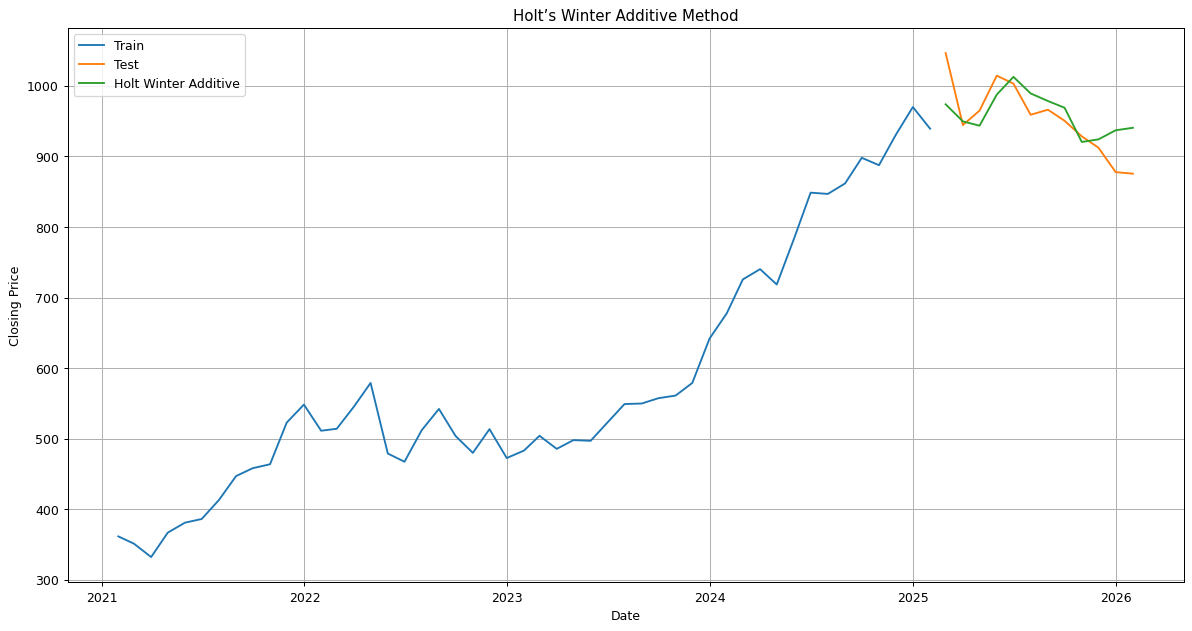

In [449]:
# Plotting
plt.figure(figsize=(16,8), dpi = 90)
plt.plot( train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_add_cr['Holt_Winter'], label='Holt Winter Additive')
plt.title('Holt’s Winter Additive Method')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid()
plt.legend(loc='best')
plt.show()

In [450]:
# Accuracy Metrics
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_add_cr['Holt_Winter'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_add_cr['Holt_Winter'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_add_cr['Holt_Winter'])),2)

rslts_h = pd.DataFrame({'Method':['Holt Winter Additive Method'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
hlwd = rslts_h[['Method', 'RMSE', 'MAE', 'MAPE']]
hlwd

,Method,RMSE,MAE,MAPE
0,Holt Winter Additive Method,36.42,28.38,3.0


In [451]:
# Auto optimized alpha, beta and gamma values

y_hat_avg_add = test_data.copy()
fit1 = ExponentialSmoothing(np.asarray(train_data['Close']) ,seasonal_periods=12 ,trend='add', seasonal='add',).fit(optimized = True)

y_hat_avg_add['Holt_Winter'] = fit1.forecast(len(test_data))

In [452]:
#outcome
y_hat_avg_add['Holt_Winter'].head()

Date
2025-02-28    954.577941
2025-03-31    956.689906
2025-04-30    971.386821
2025-05-31    965.863445
2025-06-30    986.992884
Freq: ME, Name: Holt_Winter, dtype: float64

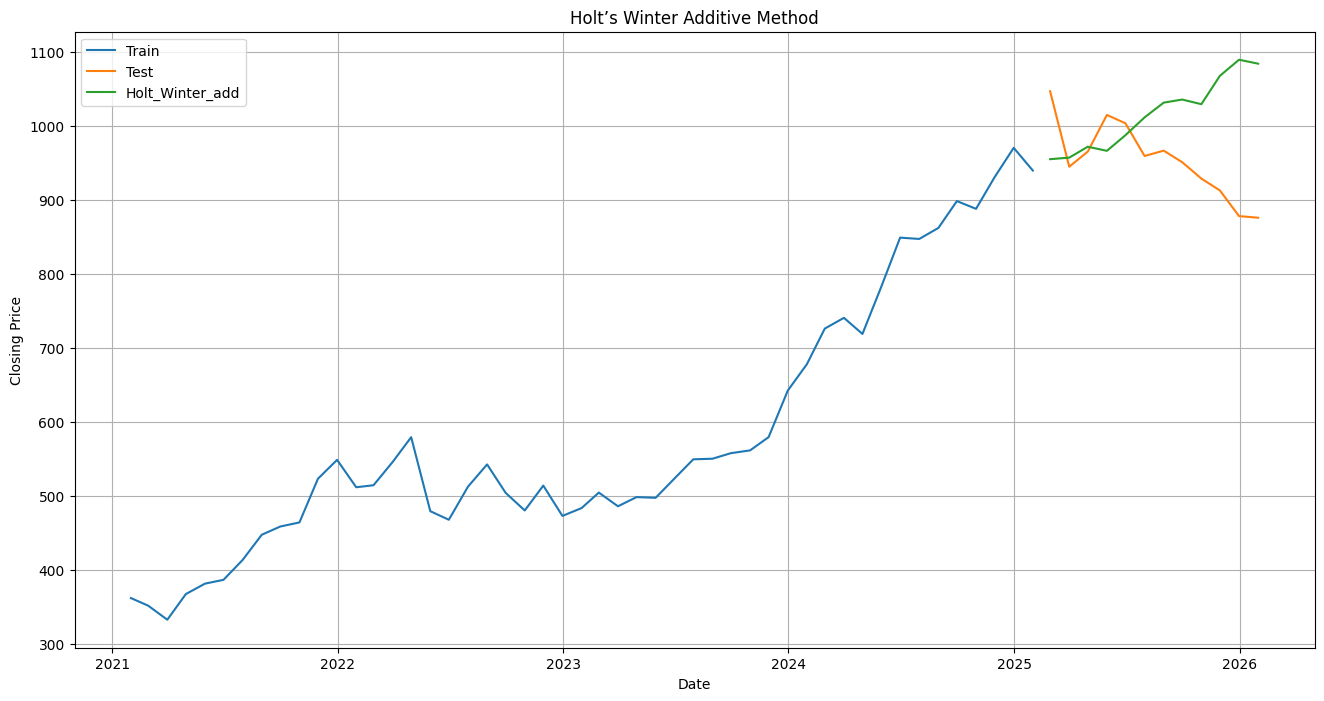

In [453]:
# Plotting
plt.figure(figsize=(16,8))
plt.plot( train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_avg_add['Holt_Winter'], label='Holt_Winter_add')
plt.title('Holt’s Winter Additive Method')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid()
plt.legend(loc='best')
plt.show()

In [454]:
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_avg_add['Holt_Winter'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg_add['Holt_Winter'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg_add['Holt_Winter'])),2)

results = pd.DataFrame({'Method':['Holt Winter Additive Method'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
hlw = results[['Method', 'RMSE', 'MAE', 'MAPE']]
hlw



,Method,RMSE,MAE,MAPE
0,Holt Winter Additive Method,110.82,87.64,9.49


## Holt's Winter Multimplicative approch

In [455]:
# our parameter ranges from (0,1)
alpha_vals = np.linspace(0.01, 0.99, 10)#10 values from the interval (0,1)
beta_vals  = np.linspace(0.00, 0.99, 10)#10values from the interval (0,1)
gamma_vals = np.linspace(0.00, 0.99, 10)#10 values from the interval (0,1)

results = []
best_score = float('inf')
best_row = None
best_fit = None
best_forecast = None

for alpha in alpha_vals:
    for beta in beta_vals:
        for gamma in gamma_vals:
            try:
                # fit model with explicit smoothing params
                model = ExponentialSmoothing(
                    y_train,
                    trend='mul',
                    seasonal='mul',
                    seasonal_periods=12,
                    initialization_method='estimated')
                fit = model.fit(
                    optimized=False,
                    smoothing_level=float(alpha),
                    smoothing_slope=float(beta),
                    smoothing_seasonal=float(gamma))
                # forecast and align
                fc = pd.Series(fit.forecast(h), index=test_index)
                metrics = compute_metrics(y_test.to_numpy(), fc.to_numpy())

                row = {
                    'alpha': round(float(alpha), 3),
                    'beta':  round(float(beta), 3),
                    'gamma': round(float(gamma), 3),
                    'RMSE': metrics['RMSE'],
                    'MAE': metrics['MAE'],
                    'MAPE': metrics['MAPE']}
                results.append(row)

                # for choosing the best by RMSE(we can also choose by MAPE or MAE but here i will choose by RMSE)
                if metrics['MAPE'] < best_score:
                    best_score = metrics['MAPE']
                    best_row = row
                    best_fit = fit
                    best_forecast = fc

            except Exception as e:
                #for skiping the invalid combinations like numerical issues
                results.append({
                    'alpha': round(float(alpha), 3),
                    'beta': round(float(beta), 3),
                    'gamma': round(float(gamma), 3),
                    'RMSE': np.nan, 'MAE': np.nan, 'MAPE': np.nan})
                continue


In [456]:
# results sorted by RMSE
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='MAPE', na_position='last').reset_index(drop=True)

# showing top 10
top10 = results_df.head()

# Top 5 parameter combinations
print(top10.to_string(index=False))

#Best parameter for our model is
print('                                                    ' 'Our best analyzed parameter result is below : ')
print(best_row)

 alpha  beta  gamma    RMSE     MAE   MAPE
 0.554  0.77   0.33 41.8565 29.4232 3.1064
 0.446  0.99   0.22 39.9809 31.0519 3.2700
 0.663  0.77   0.33 53.7319 34.3649 3.6724
 0.663  0.66   0.44 49.2262 37.0437 3.8661
 0.554  0.99   0.22 60.3654 41.1216 4.4153
                                                    Our best analyzed parameter result is below : 
{'alpha': 0.554, 'beta': 0.77, 'gamma': 0.33, 'RMSE': 41.8565, 'MAE': 29.4232, 'MAPE': np.float64(3.1064)}


In [457]:
#Manually analyzed alpha, beta and gamma values without using auto-optimize key.

y_hat_mul_cr = test_data.copy()
fit4 = ExponentialSmoothing(np.asarray(train_data['Close']) ,seasonal_periods=12 ,trend='mul', seasonal='mul',).fit(optimized = False, smoothing_level=0.554, smoothing_slope=0.77, smoothing_seasonal=0.33)
y_hat_mul_cr['Holt_Winter'] = fit4.forecast(len(test_data))
y_hat_mul_cr['Holt_Winter'].round(2)

Date
2025-02-28     947.05
2025-03-31     926.67
2025-04-30     957.23
2025-05-31     993.38
2025-06-30    1006.41
2025-07-31     982.15
2025-08-31     974.23
2025-09-30     953.72
2025-10-31     898.78
2025-11-30     921.45
2025-12-31     949.50
2026-01-31     935.94
Freq: ME, Name: Holt_Winter, dtype: float64

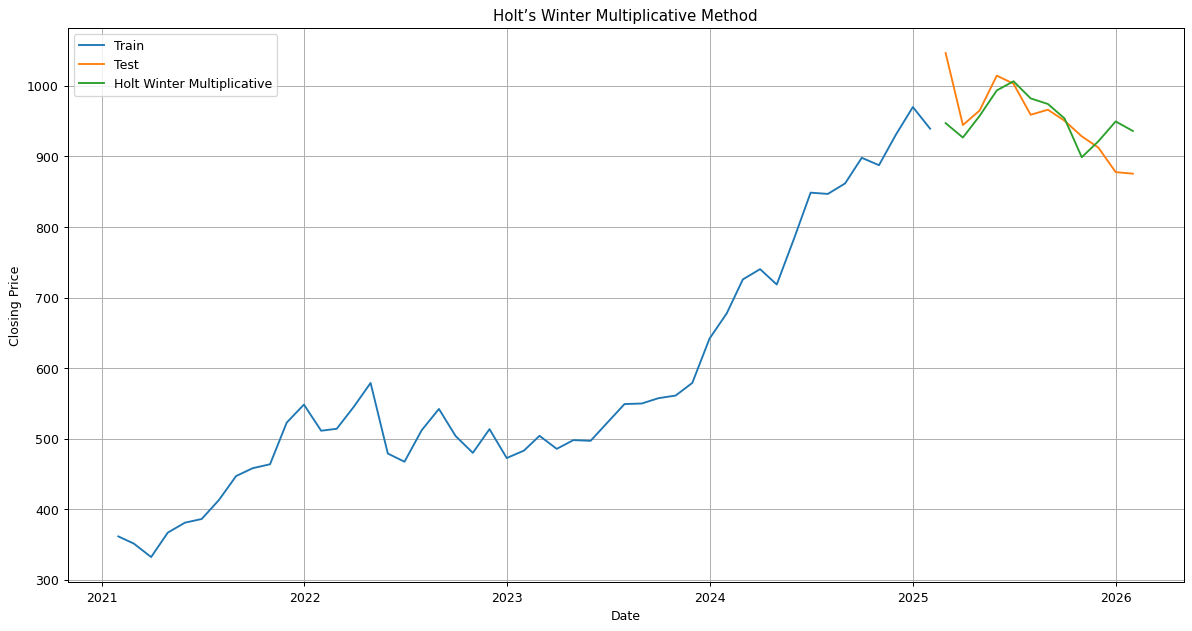

In [458]:
# Plot of Holts multiplicative method
# Plotting
plt.figure(figsize=(16,8), dpi = 90)
plt.plot( train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_mul_cr['Holt_Winter'], label='Holt Winter Multiplicative')
plt.title('Holt’s Winter Multiplicative Method')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid()
plt.legend(loc='best')
plt.show()

## Accuracy Metrics

In [459]:
# Performance metrics or Accuracy Metrics
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_mul_cr['Holt_Winter'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_mul_cr['Holt_Winter'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_mul_cr['Holt_Winter'])),2)

rslts_hwm = pd.DataFrame({'Method':['Holt Winter Multiplicative Method'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
hlms = rslts_hwm[['Method', 'RMSE', 'MAE', 'MAPE']]
hlms

,Method,RMSE,MAE,MAPE
0,Holt Winter Multiplicative Method,41.91,29.55,3.12


In [460]:
# Auto optimized alpha, beta and gamma values

y_hat_avg_mul = test_data.copy()
fit2 = ExponentialSmoothing(np.asarray(train_data['Close']) ,seasonal_periods=12 ,trend='mul', seasonal='mul',).fit(optimized = True) # trend and seasonal multiplicative
y_hat_avg_mul['Holt_Winter'] = fit2.forecast(len(test_data))


In [461]:
y_hat_avg_mul['Holt_Winter'].head()

Date
2025-02-28     974.191259
2025-03-31     983.120771
2025-04-30     999.386525
2025-05-31     993.993245
2025-06-30    1042.541252
Freq: ME, Name: Holt_Winter, dtype: float64

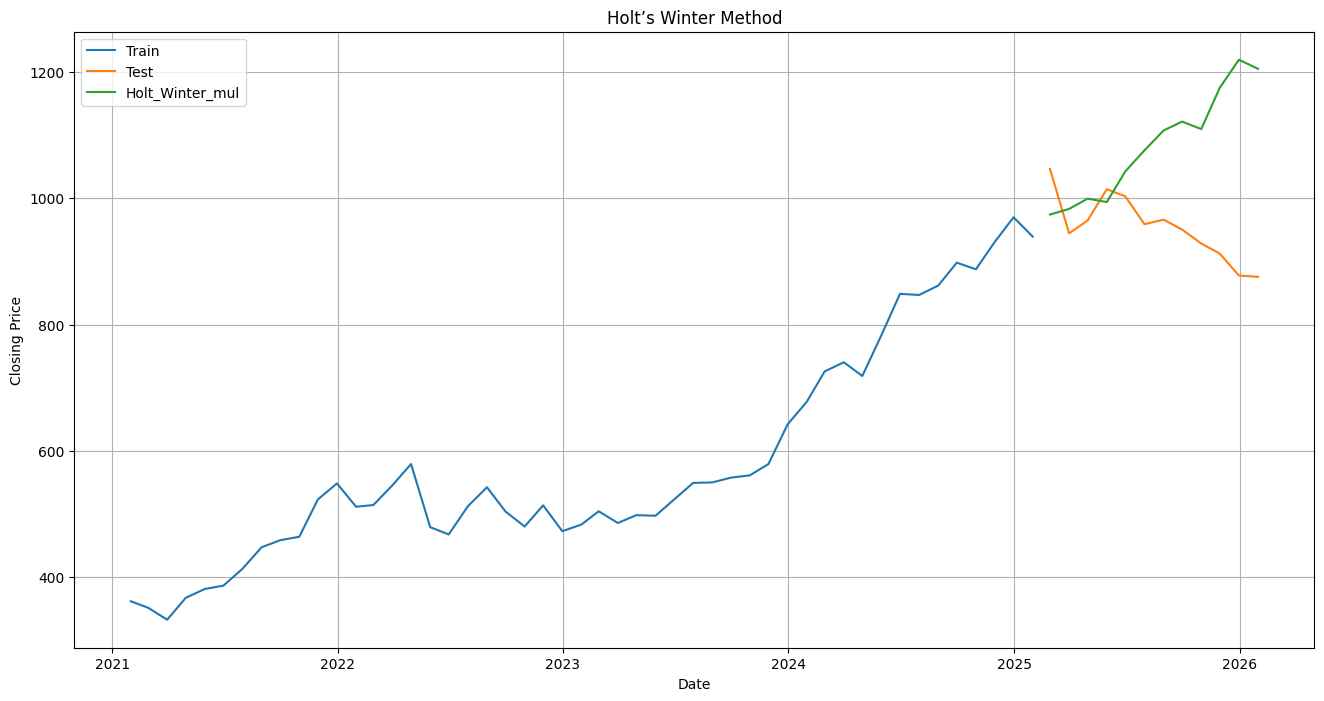

In [462]:
#Plotting
plt.figure(figsize=(16,8))
plt.plot( train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(y_hat_avg_mul['Holt_Winter'], label='Holt_Winter_mul')
plt.title('Holt’s Winter Method')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid()
plt.legend(loc='best')
plt.show()

### Accuracy metrics

In [463]:
from sklearn.metrics import mean_squared_error
rmse = np.sqrt(mean_squared_error(test_data['Close'], y_hat_avg_mul['Holt_Winter'])).round(2)
mape = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg_mul['Holt_Winter'])/test_data['Close'])*100,2)
mae  = np.round(np.mean(np.abs(test_data['Close']-y_hat_avg_mul['Holt_Winter'])),2)

results_hw = pd.DataFrame({'Method':['Holt Winter'], 'MAPE': [mape], 'RMSE': [rmse], 'MAE': [mae]})
hlm = results_hw[['Method', 'RMSE', 'MAE', 'MAPE']]
hlm

,Method,RMSE,MAE,MAPE
0,Holt Winter,182.61,145.84,15.86


#### You can see we approched both the additive approch and multiplicative trend and seasonal but the additive approch gives us the best result as you can see in accuracy matrics.

In [464]:
# Let us see graphical figure of all the exponential smoothing forecast vs actual in one plot

fitting = SimpleExpSmoothing(np.asarray(train_data['Close'])).fit(smoothing_level=alpha, optimized=False)
y_hat_avg['SES'] = fitting.forecast(len(test_data)) # number of forecasting equal to the test size

fitting1 = Holt(np.asarray(train_data['Close'])).fit(smoothing_level = 0.7,smoothing_trend = 0.9, optimized = False)
y_hat_avg['Holt_linear'] = fitting1.forecast(len(test_data))

fit3 = ExponentialSmoothing(np.asarray(train_data['Close']) ,seasonal_periods=12 ,trend='add', seasonal='add',).fit(optimized = False, smoothing_level=0.446, smoothing_slope=0.99, smoothing_seasonal=0.44)
y_hat_add_cr['Holt_Winter'] = fit3.forecast(len(test_data))

fit4 = ExponentialSmoothing(np.asarray(train_data['Close']) ,seasonal_periods=12 ,trend='mul', seasonal='mul',).fit(optimized = False, smoothing_level=0.554, smoothing_slope=0.77, smoothing_seasonal=0.33)
y_hat_mul_cr['Holt_Winter'] = fit4.forecast(len(test_data))

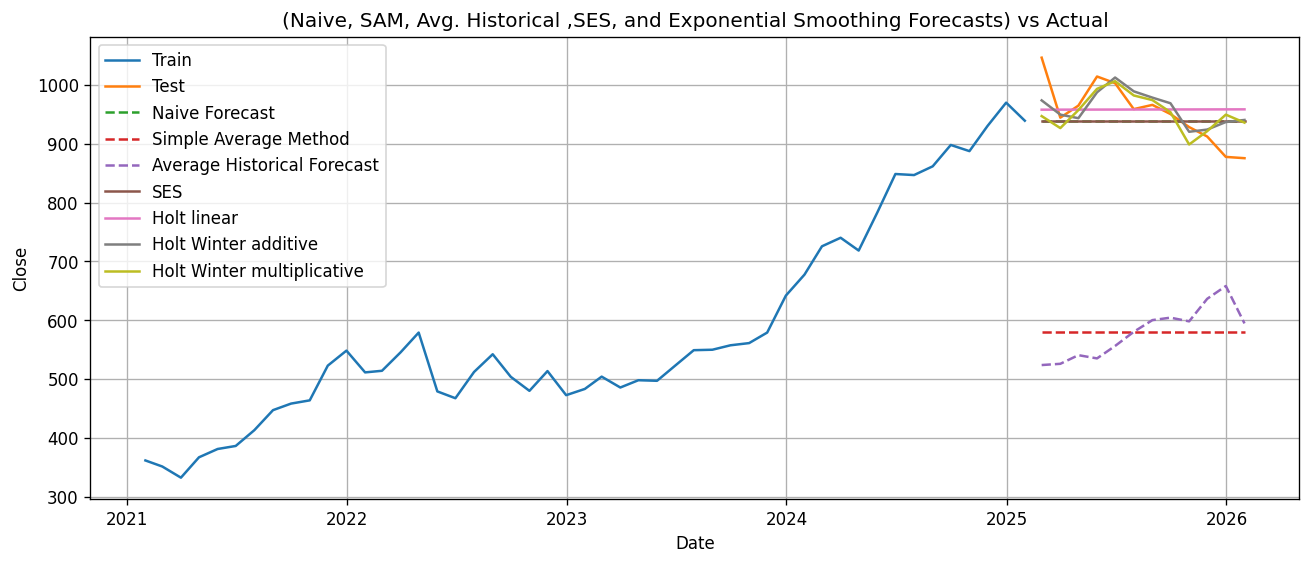

In [465]:
# Plotting all graph of all the previously done methods in one graph
plt.figure(figsize=(13,5), dpi = 120)
plt.plot(train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(naive_forecast, label='Naive Forecast', linestyle='--')
plt.plot(y_hat_simple_avg['simple_average_forecast'], label='Simple Average Method', linestyle = "--")
plt.plot(y_hat_avg_hist['average_historical_forecast'], label='Average Historical Forecast', linestyle = "--")
plt.plot(y_hat_avg['SES'], label='SES')
plt.plot(y_hat_avg['Holt_linear'], label='Holt linear')
plt.plot(y_hat_add_cr['Holt_Winter'], label='Holt Winter additive')
plt.plot(y_hat_mul_cr['Holt_Winter'], label='Holt Winter multiplicative')
plt.title('(Naive, SAM, Avg. Historical ,SES, and Exponential Smoothing Forecasts) vs Actual')
plt.xlabel('Date') 
plt.ylabel('Close')
plt.legend(loc='best')
plt.grid()
plt.show()


In [466]:
# Comparison by accuracy metrics of all methods
results_all = pd.concat([results_avg_historical,results_simple_avg,naive1,ses,hl,hlms,hlwd], ignore_index=True)
results_all

,Method,RMSE,MAE,MAPE
0,Average Historical Method,383.75,374.09,38.90
1,Simple Average Method,377.04,373.78,39.04
2,Naive Method,51.50,41.49,4.30
3,Simple Exponential Smoothing,50.44,40.00,4.17
4,Holt Linear Method,49.84,38.86,4.11
5,Holt Winter Multiplicative Method,41.91,29.55,3.12
6,Holt Winter Additive Method,36.42,28.38,3.00


As we can see clearly the Average Historical method, Simple Average Method performed poorly because our time series have trend, and we know these methods are not suitable for the series having trend.
Simple moving average method (SMA) performed partially well giving MAPE = 11.06%. For rapid changes SMA is not good choice.
Naive method, Simple Exponential Smoothing method and Holt's linear method performed good by giving 4.30%, 4.17%, 4.11% respectively MAPE. These results implies that our time series have high forecastable in short run.
Holt's winter additive model gives us the high accuracy as compare to the previous methods having 3% MAPE.

## Activity 2

Activity two is more focused on advanced statistical time series forecasting methods like ARIMA and SARIMA. The activity starts with the assessment of time series stationarity status using the Augmented Dickey-Fuller ADF test. Then to achieve the stationarity 1st and 2nd derivatives were taken out. Luckly 2nd derivative successively passed the ADF test. For the selection of initial p, q and seasonal P,  Q parameters second order series ACF and PACF plots were analyzed. For the optimal ARIMA (p, d, q) and SARIMA (P, D, Q) models systematic grid search approach employed for minimizing the AIC. After that for the statistical significance and both models were fitted to the training data and also their estimated coefficient were analyzed, revealing some instability in the coefficient of SARIMA model despite its lower AIC. At the last, forecast is created/predicted for the test period and also accuracy metrics is created for the direct comparison of forecasts with the previously done methods.

## Performing Dickey Fuller Test



In [467]:
#importing the adfuller function.
from statsmodels.tsa.stattools import adfuller

#we are going to define a function to perform and print the results of ADF test for stationarity, including ADF statistic, p and critical values.
def perform_adf_test(series, name="Time Series"):    
    # Performing Dickey Fuller test
    result = adfuller(series, autolag='AIC')
    
    print(f'Augmented Dickey Fuller Test Results for {name}:')
    print(f'  ADF Statistic: {result[0]:.2f}')
    print(f'  p-value: {result[1]:.2f}')
    print('  Critical Values:')
    for key, value in result[4].items():
        print(f'    {key}: {value:.2f}')

    # Interpretion of the p value
    if result[1] <= 0.05: # Common significance level
        print('  Result: The series is likely stationary (p-value <= 0.05).')
    else:
        print('  Result: The series is likely non-stationary (p-value > 0.05).')

#### I will apply it to the original Close price series from monthly_df to check its stationarity. This is the first step in assessing the time series properties before considering differencing.



In [468]:
# Now I will apply this defined function to the original Close price series monthly_df to check is our series is stationary or not.
perform_adf_test(monthly_df['Close'], name="Original 'Close' Price Series")

Augmented Dickey Fuller Test Results for Original 'Close' Price Series:
  ADF Statistic: -1.63
  p-value: 0.47
  Critical Values:
    1%: -3.56
    5%: -2.92
    10%: -2.60
  Result: The series is likely non-stationary (p-value > 0.05).


### Since the original Close price series is not stationary, let us apply first order differencing.



In [469]:
# First order Derivative/difference
monthly_df['Close_diff1'] = monthly_df['Close'].diff()
perform_adf_test(monthly_df['Close_diff1'].dropna(), name="First-Differenced 'Close' Price Series")

Augmented Dickey Fuller Test Results for First-Differenced 'Close' Price Series:
  ADF Statistic: -1.77
  p-value: 0.40
  Critical Values:
    1%: -3.57
    5%: -2.92
    10%: -2.60
  Result: The series is likely non-stationary (p-value > 0.05).


As our first order differenced is still non stationary, now we will again apply second order differencing to the series and also again check the ADF stationarity.

In [470]:
#Second order derivative
monthly_df['Close_diff2'] = monthly_df['Close'].diff().diff()
perform_adf_test(monthly_df['Close_diff2'].dropna(), name='Second-Differenced Close Price Series')

Augmented Dickey Fuller Test Results for Second-Differenced Close Price Series:
  ADF Statistic: -6.36
  p-value: 0.00
  Critical Values:
    1%: -3.56
    5%: -2.92
    10%: -2.60
  Result: The series is likely stationary (p-value <= 0.05).


In [471]:
#3rd order derivative
monthly_df['Close_diff3'] = monthly_df['Close'].diff().diff().diff()
perform_adf_test(monthly_df['Close_diff3'].dropna(), name='Third Differenced Close Price Series')

Augmented Dickey Fuller Test Results for Third Differenced Close Price Series:
  ADF Statistic: -7.64
  p-value: 0.00
  Critical Values:
    1%: -3.57
    5%: -2.92
    10%: -2.60
  Result: The series is likely stationary (p-value <= 0.05).


<Figure size 1350x1080 with 0 Axes>

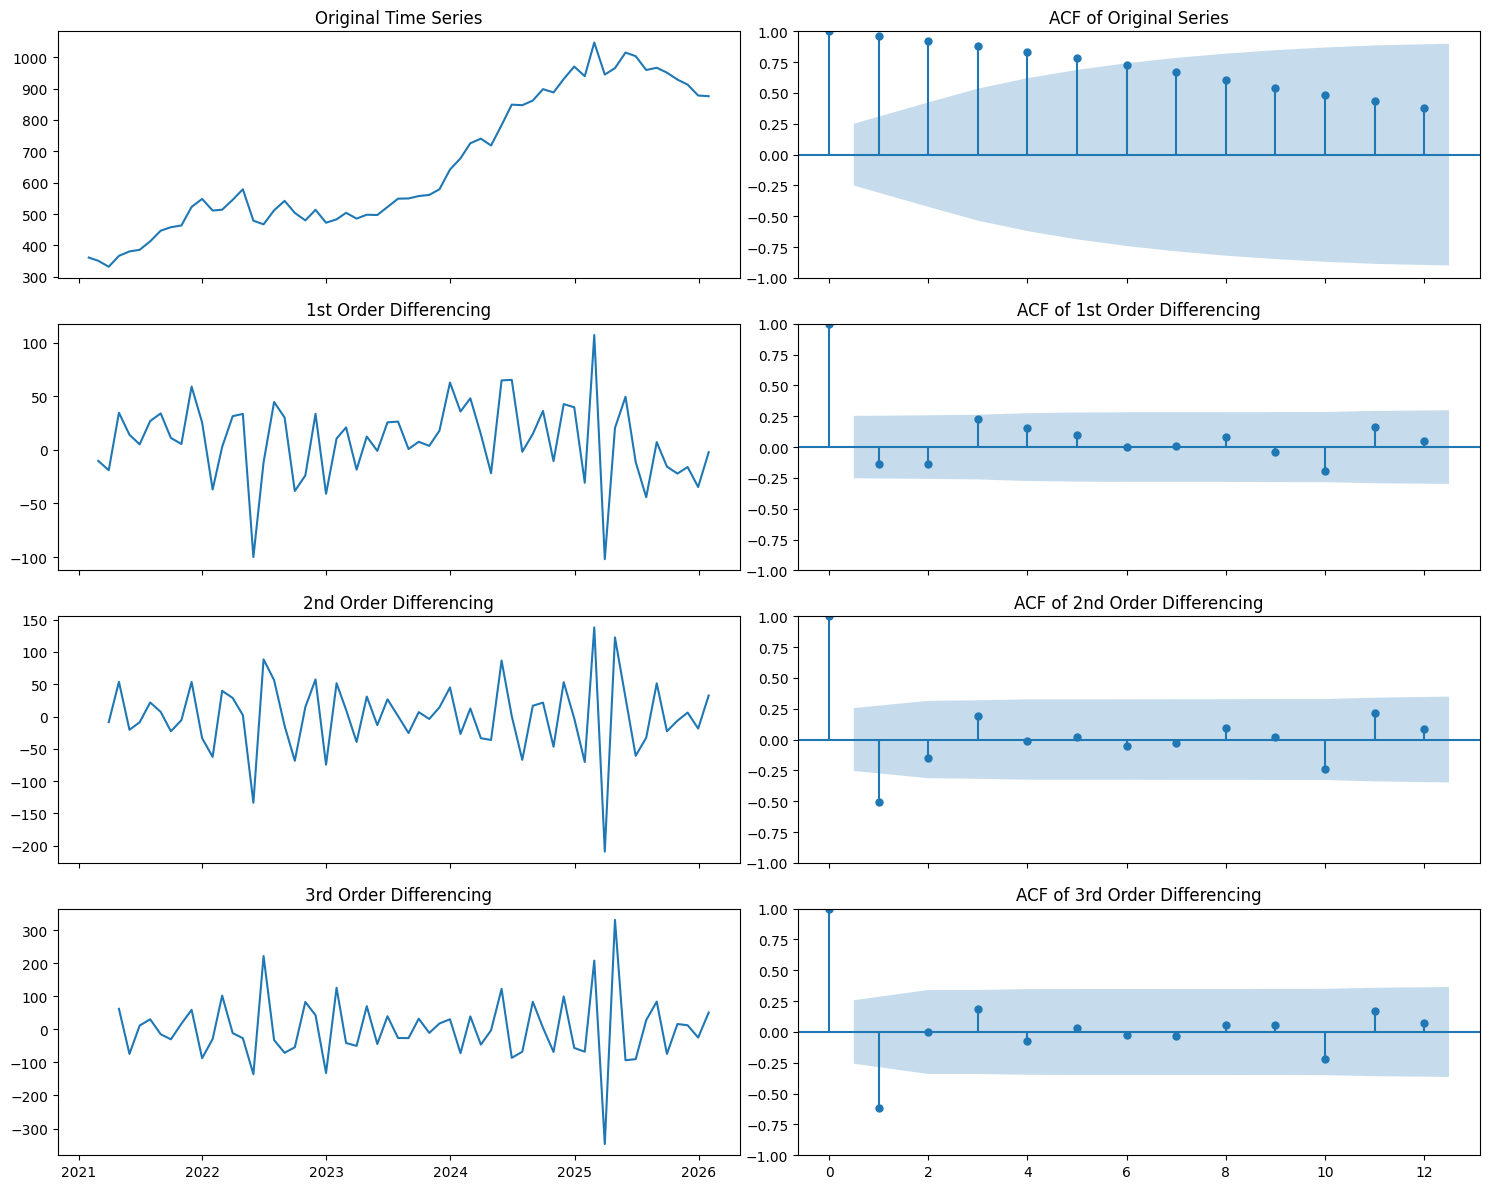

In [472]:
#Plotting
plt.figure(figsize=(15, 12), dpi=90)
fig, axes = plt.subplots(4, 2, sharex='col', figsize=(15, 12))

# Original Time Series
axes[0, 0].plot(monthly_df['Close']); axes[0, 0].set_title('Original Time Series')
plot_acf(monthly_df['Close'], lags=12, ax=axes[0, 1], title='ACF of Original Series')

# 1st Order Differencing
axes[1, 0].plot(monthly_df['Close_diff1']); axes[1, 0].set_title('1st Order Differencing')
plot_acf(monthly_df['Close_diff1'].dropna(), lags=12, ax=axes[1, 1], title='ACF of 1st Order Differencing')

# 2nd Order Differencing
axes[2, 0].plot(monthly_df['Close_diff2']); axes[2, 0].set_title('2nd Order Differencing')
plot_acf(monthly_df['Close_diff2'].dropna(), lags=12, ax=axes[2, 1], title='ACF of 2nd Order Differencing')

# 3rd Order Differencing
axes[3, 0].plot(monthly_df['Close_diff3']); axes[3, 0].set_title('3rd Order Differencing')
plot_acf(monthly_df['Close_diff3'].dropna(), lags=12, ax=axes[3, 1], title='ACF of 3rd Order Differencing')
plt.tight_layout()
plt.show()



#### Findings

Price series was non-stationary, with an ADF Statistic of -1.63 and a p-value of 0.47 (greater than 0.05).
performed first-order differencing but the series still resulted in a non-stationary, indicated by an ADF Statistic of -1.77 and a p-value of 0.40 (greater than 0.05).
After applying the second-order differencing, the series became stationary, exhibiting an ADF Statistic of -6.36 and a p-value of 0.00 (less than or equal to 0.05).

### (b) ACF and PACF Plots

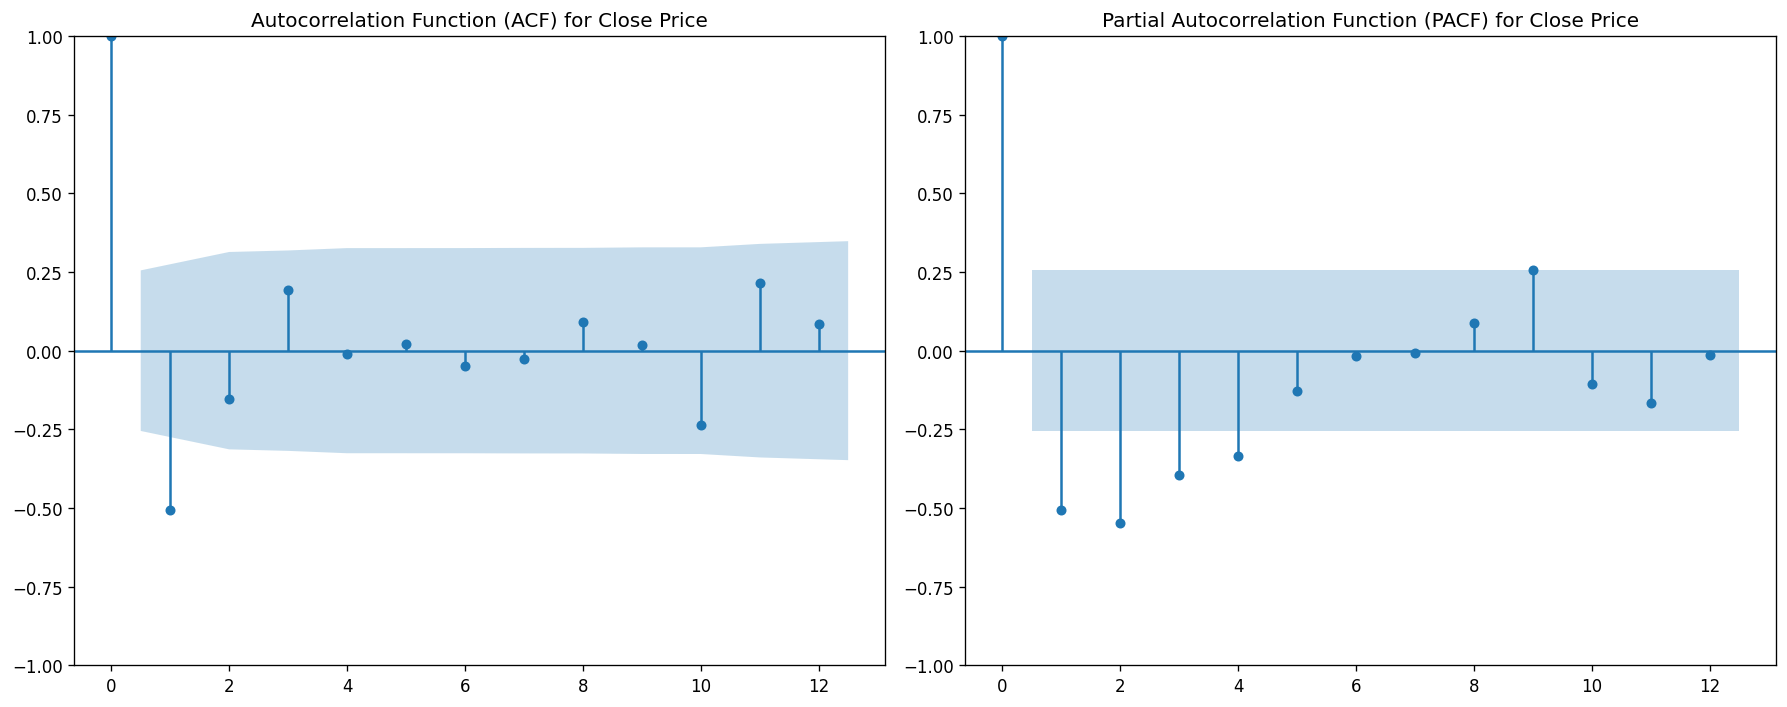

In [473]:
#Plotting
plt.figure(figsize=(15, 6), dpi=120)
# ACF plot
plt.subplot(1, 2, 1)
plot_acf(monthly_df['Close_diff2'].dropna(), lags=12, ax=plt.gca())
plt.title('Autocorrelation Function (ACF) for Close Price')

# PACF plot
plt.subplot(1, 2, 2)
plot_pacf(monthly_df['Close_diff2'].dropna(), lags=12, ax=plt.gca())
plt.title('Partial Autocorrelation Function (PACF) for Close Price')
plt.tight_layout()
plt.show()

### To find the optimal ARIMA model, I need to iterate through various combinations of p and q values for d=2, fitting the ARIMA model for every combination, and checking the lowest AIC. I will define parameter ranges, and then run a nested loop for the best optimal order.


In [474]:
# Let us start best aic to a very large number and best order to None
best_aic = float('inf')
best_order = None
p_values = range(0, 4)
q_values = range(0, 2)
d_value = 2
print("optimal ARIMA order")

# Iteration for all the combinations of p and q
for p in p_values:
    for q in q_values:
        order = (p, d_value, q)
        try:
            # fitting ARIMA model
            model = ARIMA(train_data['Close'], order=order)
            model_fit = model.fit()
            
            # getting the AIC from ARIMA model
            aic = model_fit.aic
            
            # Compare the current AIC with best aic
            if aic < best_aic:
                best_aic = aic
                best_order = order
            
            print(f'ARIMA{order} AIC: {aic:.2f}')
            
        except Exception as e:
            # Handling the errors during fitting model
            print(f'ARIMA{order} failed to fit: {e}')
            continue

print(f"\nOptimal ARIMA order: {best_order} with AIC: {best_aic:.2f}")

optimal ARIMA order
ARIMA(0, 2, 0) AIC: 492.01
ARIMA(0, 2, 1) AIC: 466.70
ARIMA(1, 2, 0) AIC: 489.52
ARIMA(1, 2, 1) AIC: 468.70
ARIMA(2, 2, 0) AIC: 468.85
ARIMA(2, 2, 1) AIC: 458.66
ARIMA(3, 2, 0) AIC: 464.35
ARIMA(3, 2, 1) AIC: 460.39

Optimal ARIMA order: (2, 2, 1) with AIC: 458.66



#### Now our optimal ARIMA order is (2,2,1), now our next step is to fit this model to the training data. with the help of model summary and we will get detailed information about the fitted model, including coefficients, standard errors, p-values, and various information criteria.



In [475]:
#As optimal ARIMA is (2,2,1),now next step is to fit model to training data with the help of model summary and we will get more detailed different informations.

print(f"Fitting the optimal ARIMA model: {best_order}")

# Fitting best ARIMA model on the training data
best_arima_model = ARIMA(train_data['Close'], order=best_order)
best_arima_model_fit = best_arima_model.fit()

# model summary
print(best_arima_model_fit.summary())

Fitting the optimal ARIMA model: (2, 2, 1)
                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                   49
Model:                 ARIMA(2, 2, 1)   Log Likelihood                -225.330
Date:                Wed, 28 Jan 2026   AIC                            458.660
Time:                        10:39:39   BIC                            466.060
Sample:                    01-31-2021   HQIC                           461.444
                         - 01-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1996      0.163     -1.226      0.220      -0.519       0.119
ar.L2         -0.5586      0.179     -3.118      0.002      -0.910      -0.207
ma.L1    

As we can see summary for ARIMA (2, 2, 1) model fits the best among all the possible combinations. Having ar.L1 = -0.1996 which is not significant statistically but still contribute in stability. As we can see ar.L2 and ma.L1 shows meaningful lag relation, implies this ARIMA (2, 2, 1) model sounds statistically strong.

In [476]:
# forecast of ARIMA model with (2,2,1)
start_index = len(train_data)
end_index = len(monthly_df) - 1

arima_forecast_series = best_arima_model_fit.predict(start=start_index, end=end_index, dynamic=False)

# Creating the DataFrame for the ARIMA forecast results, aligning with the test_data index
y_hat_arima = test_data.copy()
y_hat_arima['ARIMA_forecast'] = arima_forecast_series.values
display(y_hat_arima.round(2))

,Close,ARIMA_forecast
Date,,
2025-02-28,1046.39,953.25
2025-03-31,944.41,997.70
2025-04-30,964.84,1011.09
2025-05-31,1014.36,1013.70
2025-06-30,1003.06,1035.80
2025-07-31,958.91,1060.04
2025-08-31,966.12,1072.96
2025-09-30,950.49,1086.94
2025-10-31,928.37,1107.04


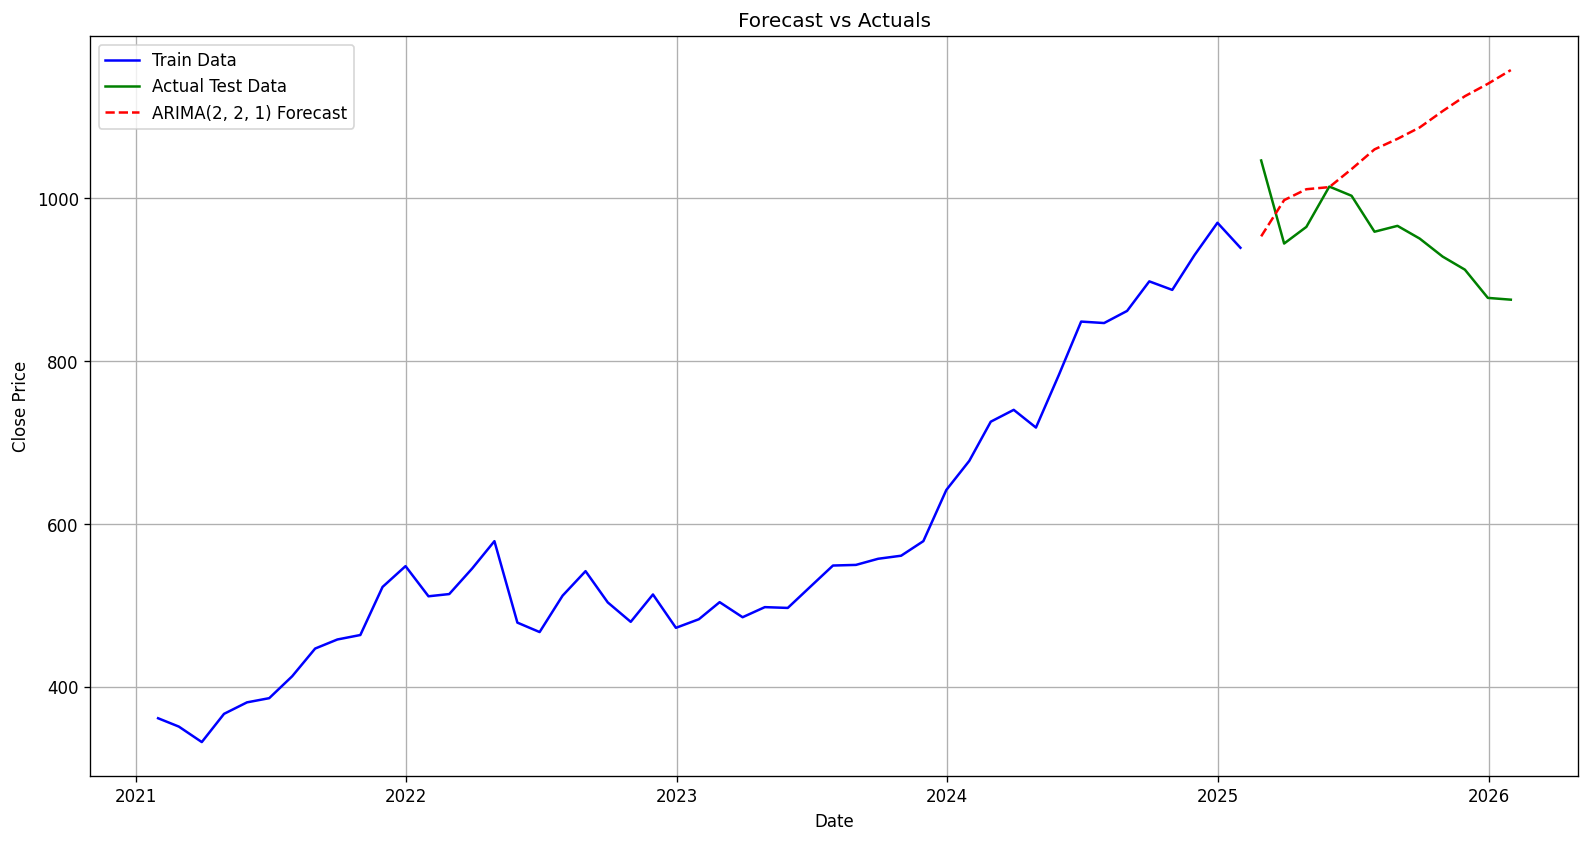

In [477]:
# Plotting the ARIMA forecast against the actual values
plt.figure(figsize=(16, 8),dpi = 120)
plt.plot(train_data['Close'], label='Train Data', color='blue')
plt.plot(test_data['Close'], label='Actual Test Data', color='green')
plt.plot(y_hat_arima['ARIMA_forecast'], label=f'ARIMA{best_order} Forecast', color='red', linestyle='--')
plt.title('Forecast vs Actuals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

## Accuracy metrics

In [478]:
# Accuracy metrics for ARIMA
rmse_arima = np.sqrt(mean_squared_error(test_data['Close'], y_hat_arima['ARIMA_forecast'])).round(2)
mape_arima = np.round(np.mean(np.abs(test_data['Close'] - y_hat_arima['ARIMA_forecast']) / test_data['Close']) * 100, 2)
mae_arima = np.round(np.mean(np.abs(test_data['Close'] - y_hat_arima['ARIMA_forecast'])), 2)

results_arima = pd.DataFrame({'Method': [f'ARIMA{best_order}'], 'RMSE': [rmse_arima], 'MAE': [mae_arima], 'MAPE': [mape_arima]})
results_arima

,Method,RMSE,MAE,MAPE
0,"ARIMA(2, 2, 1)",152.99,125.58,13.61


In [479]:
# Comparison by accuracy metrics of all the previous methods.
results_all = pd.concat([sma,results_avg_historical,results_simple_avg,naive1,ses,hl,hlms,hlwd,results_arima], ignore_index=True)
results_all

,Method,RMSE,MAE,MAPE
0,Simple Moving Averages method,118.56,107.75,11.06
1,Average Historical Method,383.75,374.09,38.90
2,Simple Average Method,377.04,373.78,39.04
3,Naive Method,51.50,41.49,4.30
4,Simple Exponential Smoothing,50.44,40.00,4.17
5,Holt Linear Method,49.84,38.86,4.11
6,Holt Winter Multiplicative Method,41.91,29.55,3.12
7,Holt Winter Additive Method,36.42,28.38,3.00
8,"ARIMA(2, 2, 1)",152.99,125.58,13.61


## Till now
we have seen and analyzed that, the Holt-Winters Additive Method shows the best performance with the lowest MAPE value 3.00%, making it the most suitable model for forecasting the Costco 'Close' price series among those evaluated till now.

In [480]:
#Creating a seasonally differenced series for Close price from the monthly_df DataFrame, with period = 12 months,for seasonal ACF and PACF analysis and SARIMA model fitting.

monthly_df['Close_seasonal_diff'] = monthly_df['Close'].diff(periods=12)
monthly_df.head()

,Close,Close_diff1,Close_diff2,Close_diff3,Close_seasonal_diff
Date,,,,,
2021-01-31,361.548000,NaN,NaN,NaN,NaN
2021-02-28,351.288421,-10.259579,NaN,NaN,NaN
2021-03-31,332.294783,-18.993638,-8.734059,NaN,NaN
2021-04-30,366.937619,34.642836,53.636475,62.370534,NaN
2021-05-31,381.047500,14.109881,-20.532955,-74.169430,NaN


#### For the dentification of appropriate seasonal 'P' and 'Q' components for the SARIMA model, we will plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots for the seasonally differenced Close price series.

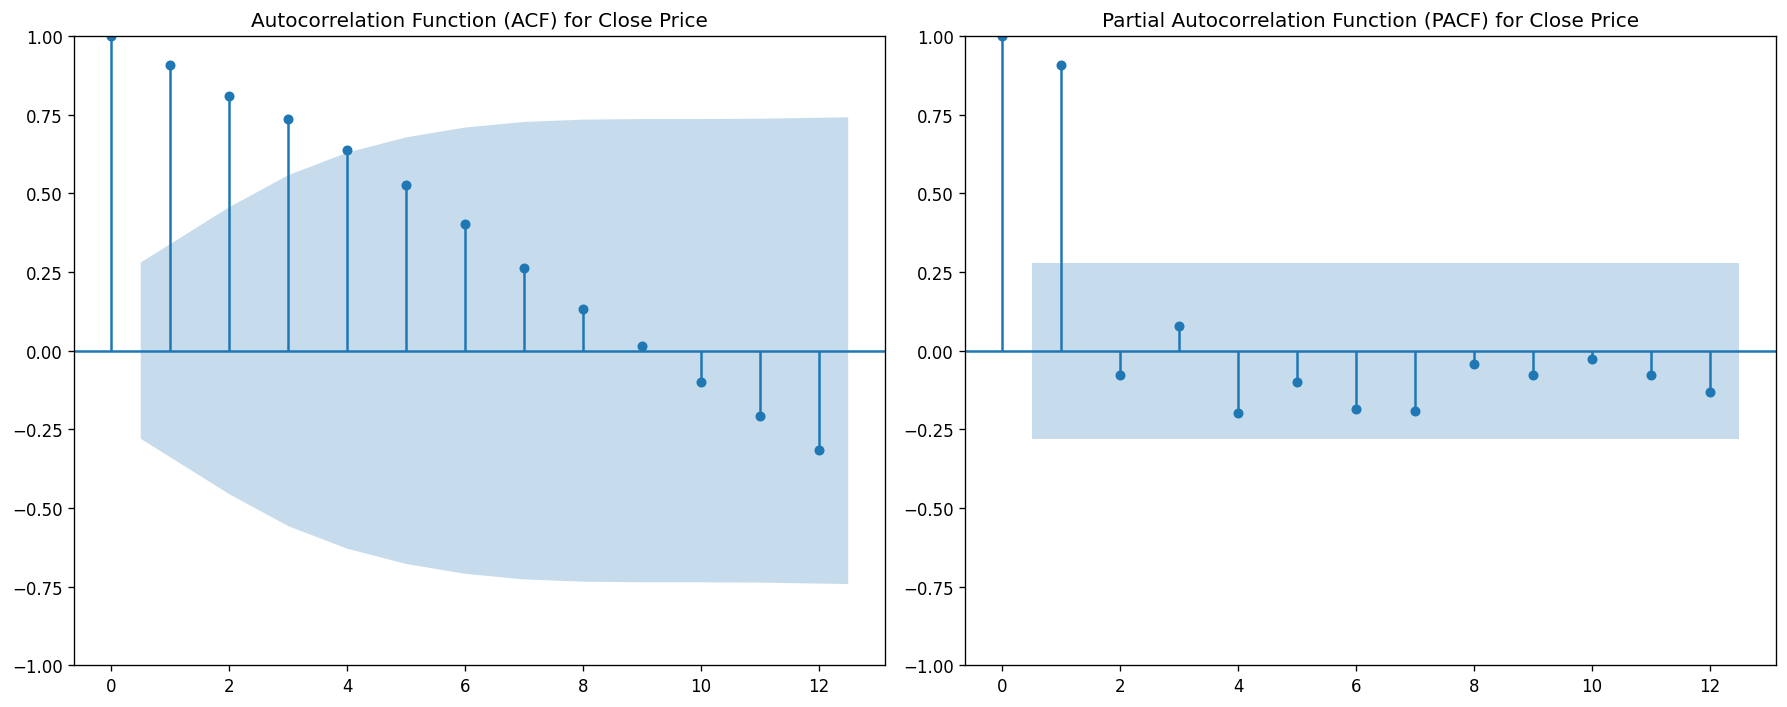

In [481]:
plt.figure(figsize=(15, 6), dpi = 120)
#ACF
plt.subplot(1, 2, 1)
plot_acf(monthly_df['Close_seasonal_diff'].dropna(), lags=12, ax=plt.gca())
plt.title('Autocorrelation Function (ACF) for Close Price')
#PACF
plt.subplot(1, 2, 2)
plot_pacf(monthly_df['Close_seasonal_diff'].dropna(), lags=12, ax=plt.gca())
plt.title('Partial Autocorrelation Function (PACF) for Close Price')
plt.tight_layout()
plt.show()

#### Selecting the Optimal SARIMA Model using AIC

In [482]:
# for finding optimal SARIMA model, again we will implement a grid search iterating for different combinations of p, q and P, Q parameters, while keeping d=2, D=1, and m=12 fixed.
#ranges of small p and q
p_values = range(0, 3)
q_values = range(0, 3)
#ranges of capital P and Q
P_values = range(0, 2)
Q_values = range(0, 2)
# Our fixed parameters
d_value = 2
D_value = 1
m_value = 12

# best aic to a very large number and best order to None
best_aic = float('inf')
best_order = None
best_seasonal_order = None

# Iterating through all the combinations of p, q, P, and Q
for p in p_values:
    for q in q_values:
        for P in P_values:
            for Q in Q_values:
                order = (p, d_value, q)
                seasonal_order = (P, D_value, Q, m_value)
                try:
                    #SARIMAX model
                    model = SARIMAX(train_data['Close'],
                                    order=order,
                                    seasonal_order=seasonal_order,
                                    enforce_stationarity=False,
                                    enforce_invertibility=False)
                    model_fit = model.fit(disp=False)

                    # Getting AIC from the fitted model
                    aic = model_fit.aic

                    # Comparing the current AIC with the best aic
                    if aic < best_aic:
                        best_aic = aic
                        best_order = order
                        best_seasonal_order = seasonal_order

                    print(f'SARIMA{order}{seasonal_order} AIC: {aic:.2f}')

                except Exception as e:
                    # Handling errors during model fitting
                    # print(f'SARIMA{order}{seasonal_order} failed to fit: {e}')
                    continue

print(f"\nOptimal SARIMA order: {best_order}{best_seasonal_order} with AIC: {best_aic:.2f}")

SARIMA(0, 2, 0)(0, 1, 0, 12) AIC: 378.76
SARIMA(0, 2, 0)(0, 1, 1, 12) AIC: 242.65
SARIMA(0, 2, 0)(1, 1, 0, 12) AIC: 255.43
SARIMA(0, 2, 0)(1, 1, 1, 12) AIC: 242.99
SARIMA(0, 2, 1)(0, 1, 0, 12) AIC: 353.54
SARIMA(0, 2, 1)(0, 1, 1, 12) AIC: 222.51
SARIMA(0, 2, 1)(1, 1, 0, 12) AIC: 243.92
SARIMA(0, 2, 1)(1, 1, 1, 12) AIC: 223.78
SARIMA(0, 2, 2)(0, 1, 0, 12) AIC: 338.62
SARIMA(0, 2, 2)(0, 1, 1, 12) AIC: 212.50
SARIMA(0, 2, 2)(1, 1, 0, 12) AIC: 245.78
SARIMA(0, 2, 2)(1, 1, 1, 12) AIC: 214.05
SARIMA(1, 2, 0)(0, 1, 0, 12) AIC: 377.17
SARIMA(1, 2, 0)(0, 1, 1, 12) AIC: 242.15
SARIMA(1, 2, 0)(1, 1, 0, 12) AIC: 243.73
SARIMA(1, 2, 0)(1, 1, 1, 12) AIC: 244.15
SARIMA(1, 2, 1)(0, 1, 0, 12) AIC: 355.41
SARIMA(1, 2, 1)(0, 1, 1, 12) AIC: 224.51
SARIMA(1, 2, 1)(1, 1, 0, 12) AIC: 234.83
SARIMA(1, 2, 1)(1, 1, 1, 12) AIC: 225.76
SARIMA(1, 2, 2)(0, 1, 0, 12) AIC: 336.37
SARIMA(1, 2, 2)(0, 1, 1, 12) AIC: 211.91
SARIMA(1, 2, 2)(1, 1, 0, 12) AIC: 233.05
SARIMA(1, 2, 2)(1, 1, 1, 12) AIC: 213.52
SARIMA(2, 2, 0)(

In [483]:
#fitting our model to the training data.
best_sarima_model = SARIMAX(train_data['Close'],
                                order=best_order,
                                seasonal_order=best_seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)
best_sarima_model_fit = best_sarima_model.fit(disp=False)

print(best_sarima_model_fit.summary())

                                      SARIMAX Results                                       
Dep. Variable:                                Close   No. Observations:                   49
Model:             SARIMAX(2, 2, 2)x(1, 1, [1], 12)   Log Likelihood                 -97.991
Date:                              Wed, 28 Jan 2026   AIC                            209.981
Time:                                      10:39:47   BIC                            216.952
Sample:                                  01-31-2021   HQIC                           211.342
                                       - 01-31-2025                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9376      0.350     -2.678      0.007      -1.624      -0.251
ar.L2         -0.54

In [484]:
# forecasts of SARIMA
start_index = len(train_data)
end_index = len(monthly_df) - 1

sarima_forecast_series = best_sarima_model_fit.predict(start=start_index, end=end_index)

# Creating a DataFrame for the SARIMA forecast results
y_hat_sarima = test_data.copy()
y_hat_sarima['SARIMA_forecast'] = sarima_forecast_series.values

display(y_hat_sarima.round(2))

,Close,SARIMA_forecast
Date,,
2025-02-28,1046.39,1023.39
2025-03-31,944.41,1024.53
2025-04-30,964.84,966.08
2025-05-31,1014.36,1044.64
2025-06-30,1003.06,1090.99
2025-07-31,958.91,1066.54
2025-08-31,966.12,1079.91
2025-09-30,950.49,1098.06
2025-10-31,928.37,1066.28


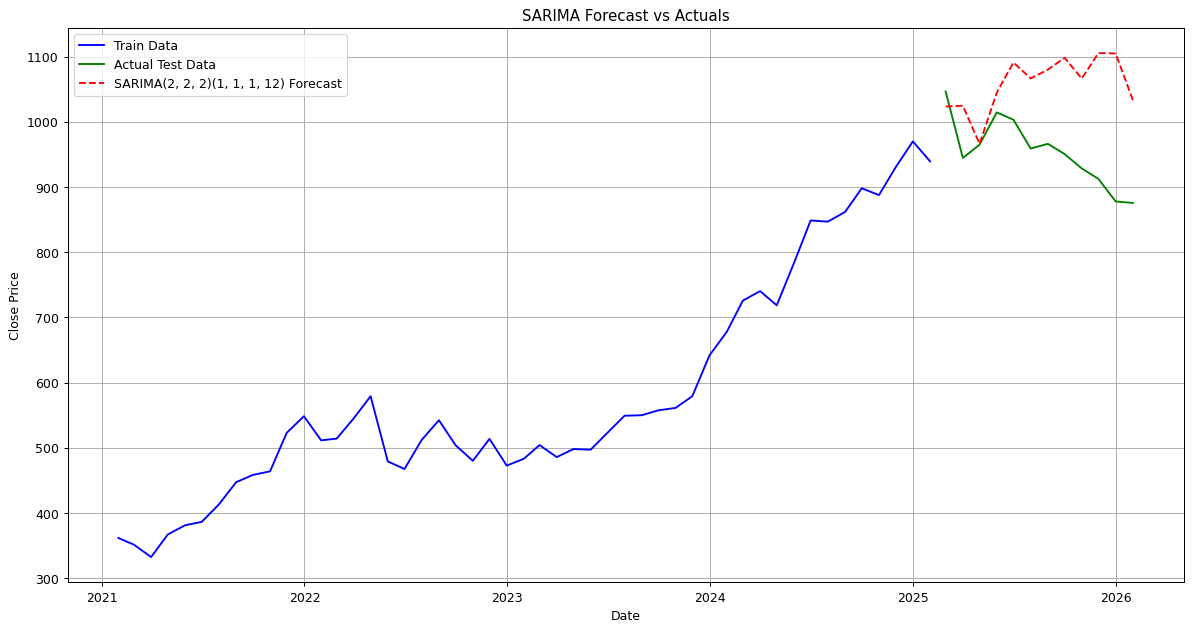

In [485]:
# Plotting forecast against the historical training data and the actual test data.
plt.figure(figsize=(16,8), dpi = 90)
plt.plot(train_data['Close'], label='Train Data', color='blue')
plt.plot(test_data['Close'], label='Actual Test Data', color='green')
plt.plot(y_hat_sarima['SARIMA_forecast'], label=f'SARIMA{best_order}{best_seasonal_order} Forecast', color='red', linestyle='--')
plt.title('SARIMA Forecast vs Actuals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [486]:
# Accuracy Metrics
rmse_sarima = np.sqrt(mean_squared_error(test_data['Close'], y_hat_sarima['SARIMA_forecast'])).round(2)
mape_sarima = np.round(np.mean(np.abs(test_data['Close'] - y_hat_sarima['SARIMA_forecast']) / test_data['Close']) * 100, 2)
mae_sarima = np.round(np.mean(np.abs(test_data['Close'] - y_hat_sarima['SARIMA_forecast'])), 2)

results_sarima = pd.DataFrame({'Method': [f'SARIMA{best_order}{best_seasonal_order}'], 'RMSE': [rmse_sarima], 'MAE': [mae_sarima], 'MAPE': [mape_sarima]})
results_sarima

,Method,RMSE,MAE,MAPE
0,"SARIMA(2, 2, 2)(1, 1, 1, 12)",127.34,108.93,11.75


In [487]:
# Comparison by accuracy metrics of all the previous methods.
results_all = pd.concat([sma,results_avg_historical,results_simple_avg,naive1,ses,hl,hlms,hlwd,results_arima,results_sarima], ignore_index=True)
results_all

,Method,RMSE,MAE,MAPE
0,Simple Moving Averages method,118.56,107.75,11.06
1,Average Historical Method,383.75,374.09,38.90
2,Simple Average Method,377.04,373.78,39.04
3,Naive Method,51.50,41.49,4.30
4,Simple Exponential Smoothing,50.44,40.00,4.17
5,Holt Linear Method,49.84,38.86,4.11
6,Holt Winter Multiplicative Method,41.91,29.55,3.12
7,Holt Winter Additive Method,36.42,28.38,3.00
8,"ARIMA(2, 2, 1)",152.99,125.58,13.61
9,"SARIMA(2, 2, 2)(1, 1, 1, 12)",127.34,108.93,11.75


In [488]:
# Comparison of both the Predictive models ARIMA and SARIMA.
results_all_A_S = pd.concat([results_arima,results_sarima], ignore_index=True)
results_all_A_S

,Method,RMSE,MAE,MAPE
0,"ARIMA(2, 2, 1)",152.99,125.58,13.61
1,"SARIMA(2, 2, 2)(1, 1, 1, 12)",127.34,108.93,11.75


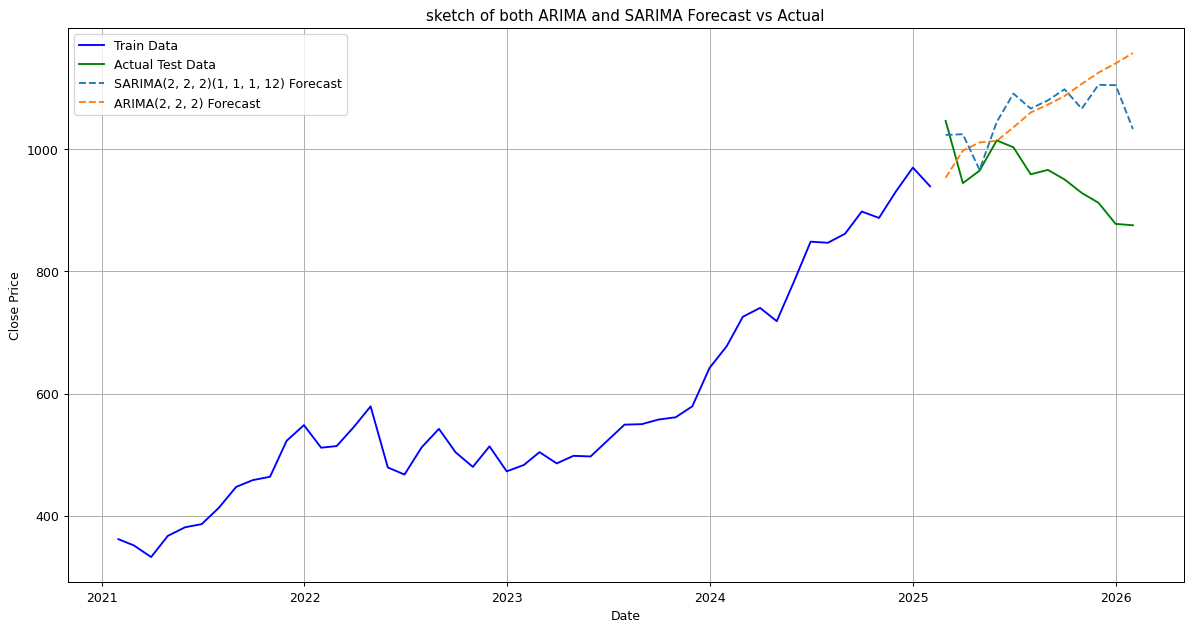

In [489]:
# sketch of both ARIMA and SARIMA in single figure
plt.figure(figsize=(16,8), dpi = 90)
plt.plot(train_data['Close'], label='Train Data', color='blue')
plt.plot(test_data['Close'], label='Actual Test Data', color='green')
plt.plot(y_hat_sarima['SARIMA_forecast'], label=f'SARIMA{best_order}{best_seasonal_order} Forecast', linestyle='--')
plt.plot(y_hat_arima['ARIMA_forecast'], label=f'ARIMA{best_order} Forecast', linestyle='--')
plt.title('sketch of both ARIMA and SARIMA Forecast vs Actual')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [490]:
# Comparison by accuracy metrics of all the previous methods.
results_all_g = pd.concat([sma,results_avg_historical,results_simple_avg,naive1,ses,hl,hlms,hlwd,results_arima,results_sarima], ignore_index=True)
results_all_g

,Method,RMSE,MAE,MAPE
0,Simple Moving Averages method,118.56,107.75,11.06
1,Average Historical Method,383.75,374.09,38.90
2,Simple Average Method,377.04,373.78,39.04
3,Naive Method,51.50,41.49,4.30
4,Simple Exponential Smoothing,50.44,40.00,4.17
5,Holt Linear Method,49.84,38.86,4.11
6,Holt Winter Multiplicative Method,41.91,29.55,3.12
7,Holt Winter Additive Method,36.42,28.38,3.00
8,"ARIMA(2, 2, 1)",152.99,125.58,13.61
9,"SARIMA(2, 2, 2)(1, 1, 1, 12)",127.34,108.93,11.75


## **Activity 3**

**Work Flow of Activity 3**
In activity three by using linear regression we will forecast our time series forecasting by using lagged values of second difference as predictors, with justified lag order by PACF plot of second order difference. Preparation of data with creating lag features, and by dividing it into testing and training datasets, keeping temporal order. We will create the forecast for our test period after fitting the linear regression model to predict the second difference close price. To revert into original close series forecast we will do twice inverse transformation, then see visualization for the forecast vs actual, accuracy metrics and linear regression comparison with all the previous models

## Preparing Data

In [491]:
"""
Work flow: for preparing the data for L.R, I will create a new DataFrame, add a lagged version of 2nd derivative series, handling NaN values, and then define the independent
and dependent variables.
"""
regression_df = monthly_df.copy()
# Creating a lagged version for 2nd derivative
regression_df['Close_diff2_lag1'] = regression_df['Close_diff2'].shift(1)

# Droping null rows
regression_df_cleaned = regression_df.dropna()

# Let us Define independent and dependent variables
X = regression_df_cleaned[['Close_diff2_lag1']]
y = regression_df_cleaned['Close_diff2']
print(regression_df_cleaned.head())

print('\nX head:')
print(X.head())

print('\nY head:')
print(y.head())

                 Close  Close_diff1  Close_diff2  Close_diff3  \
Date                                                            
2022-01-31  511.288500   -37.009682   -62.526911   -29.002236   
2022-02-28  514.016316     2.727816    39.737498   102.264409   
2022-03-31  545.445652    31.429336    28.701521   -11.035977   
2022-04-30  578.978500    33.532848     2.103511   -26.598009   
2022-05-31  478.951905  -100.026595  -133.559443  -135.662955   

            Close_seasonal_diff  Close_diff2_lag1  
Date                                               
2022-01-31           149.740500        -33.524675  
2022-02-28           162.727895        -62.526911  
2022-03-31           213.150870         39.737498  
2022-04-30           212.040881         28.701521  
2022-05-31            97.904405          2.103511  

X head:
            Close_diff2_lag1
Date                        
2022-01-31        -33.524675
2022-02-28        -62.526911
2022-03-31         39.737498
2022-04-30         28.7015

## Split Data into Training and Testing Sets

In [492]:
""" Flow chart: for the preparation of training and evaluation of the model, I will split the X lagged features and y target 
variable dataframes into training and testing sets, by keeping in mind that the temporal order is maintained and the split is 
aligned with our previous defined forecast horizon.
"""
X_train = X.loc[X.index.isin(train_data.index)]
X_test = X.loc[X.index.isin(test_data.index)]
y_train = y.loc[y.index.isin(train_data.index)]
y_test = y.loc[y.index.isin(test_data.index)]
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Verifing that the test set length matches the forecast_horizon
print(f"Length of y_test: {len(y_test)}")
print(f"Forecast horizon: {forecast_horizon}")

Shape of X_train: (37, 1)
Shape of X_test: (12, 1)
Shape of y_train: (37,)
Shape of y_test: (12,)
Length of y_test: 12
Forecast horizon: 12


### Fit Linear Regression Model and Forecast

In [493]:
#fitting LinearRegression using training set and then forecasts for test period.
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predicting the 2nd derivative values for the test
linear_regression_diff2_forecast = lr_model.predict(X_test)

# Creating a Series for the forecasted 2nd derivative values with the correct index
linear_regression_diff2_forecast_series = pd.Series(linear_regression_diff2_forecast, index=y_test.index)

In [494]:
"""
Self workflow note: 

Inverse transform from Close 2nd derivative to Close first derivative, for that I need the last actual Close first derivative value from the training period 
as the starting point, then the index of monthly_df might have more values than training data or test data due to null values from the initial differencing.
Its mean I need to find the last valid Close first derivative before the test period starts. Moreover, As our forecast is twice differenced series, 
so I will take inverse transform twice to get predictions on original Close price.

"""
last_train_diff1_value = monthly_df['Close_diff1'].loc[train_data.index[-1]]

# first derivative forecast series
linear_regression_diff1_forecast = [last_train_diff1_value]

#Second derivative forecasts to get first derivative forecasts
for i in range(len(linear_regression_diff2_forecast_series)):
    linear_regression_diff1_forecast.append(linear_regression_diff1_forecast[-1] + linear_regression_diff2_forecast_series.iloc[i])

#. Removing the initial value
linear_regression_diff1_forecast = linear_regression_diff1_forecast[1:]

# Creating a Series for the first derivative forecast
linear_regression_diff1_forecast_series = pd.Series(linear_regression_diff1_forecast, index=y_test.index)

# Inverse transform from Close first derivative to original Close. I need the last actual Close value from the training period as a starting point
last_train_close_value = train_data['Close'].iloc[-1]

# statrting our original close price forecast
linear_regression_forecast_close = [last_train_close_value]

# Accumulate the first derivative forecast to get original Close price forecast
for i in range(len(linear_regression_diff1_forecast_series)):
    linear_regression_forecast_close.append(linear_regression_forecast_close[-1] + linear_regression_diff1_forecast_series.iloc[i])

# Remove the initial value used for accumulation
linear_regression_forecast_close = linear_regression_forecast_close[1:]

#final linear regression forecast dataframe
y_hat_lr = test_data.copy()
y_hat_lr['Linear_Regression_Forecast'] = linear_regression_forecast_close

y_hat_lr

,Close,Linear_Regression_Forecast
Date,,
2025-02-28,1046.391579,927.850953
2025-03-31,944.406190,873.670762
2025-04-30,964.835238,880.228825
2025-05-31,1014.363810,848.583904
2025-06-30,1003.061500,806.580633
2025-07-31,958.914545,781.053728
2025-08-31,966.118571,763.652257
2025-09-30,950.485714,729.252728
2025-10-31,928.368696,699.992375


## Accuracy Metrics

In [495]:
#Accuracy Metrics
rmse_lr = np.sqrt(mean_squared_error(test_data['Close'], y_hat_lr['Linear_Regression_Forecast'])).round(2)
mape_lr = np.round(np.mean(np.abs(test_data['Close'] - y_hat_lr['Linear_Regression_Forecast']) / test_data['Close']) * 100, 2)
mae_lr = np.round(np.mean(np.abs(test_data['Close'] - y_hat_lr['Linear_Regression_Forecast'])), 2)

results_lr = pd.DataFrame({'Method': ['Linear Regression (AR1)'], 'RMSE': [rmse_lr], 'MAE': [mae_lr], 'MAPE': [mape_lr]})
results_lr

,Method,RMSE,MAE,MAPE
0,Linear Regression (AR1),194.08,184.35,19.58


## Visualization the regaration forecast against the actual training and testing data.

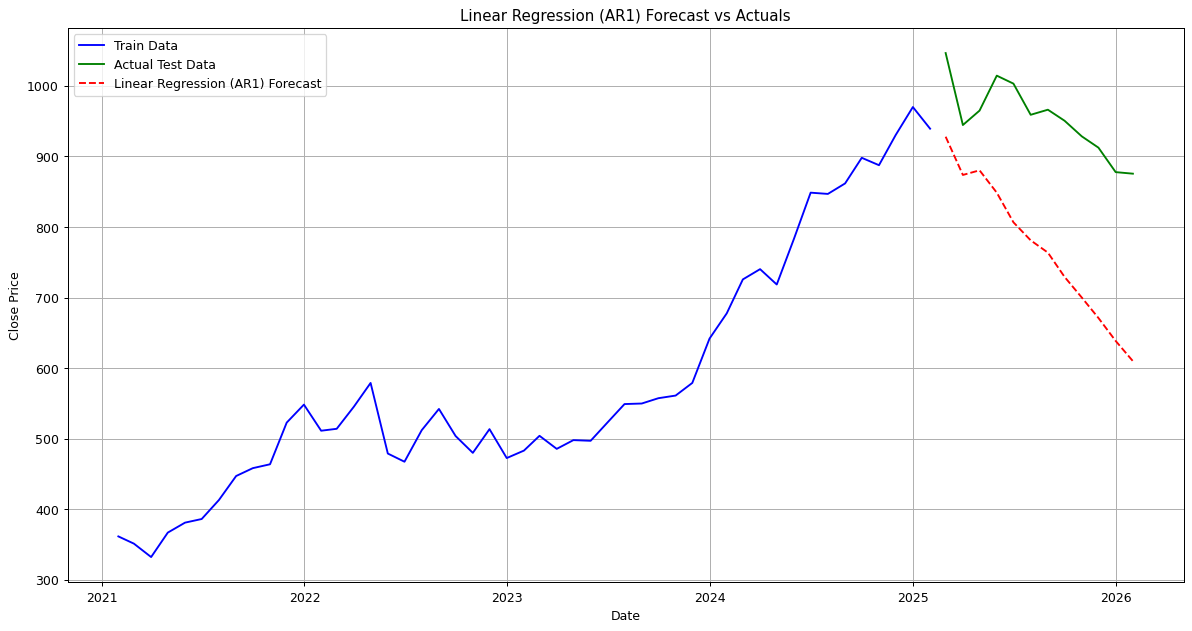

In [496]:
#Plotting LR forcast
plt.figure(figsize=(16, 8), dpi = 90)
plt.plot(train_data['Close'], label='Train Data', color='blue')
plt.plot(test_data['Close'], label='Actual Test Data', color='green')
plt.plot(y_hat_lr['Linear_Regression_Forecast'], label='Linear Regression (AR1) Forecast', color='red', linestyle='--')
plt.title('Linear Regression (AR1) Forecast vs Actuals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

## Accuracy Metrics with all the previously evaluated models.

In [497]:
# Comparison by accuracy metrics of all the previous methods.
results_all = pd.concat([sma,results_avg_historical,results_simple_avg,naive1,ses,hl,hlms,hlwd,results_arima,results_sarima,results_lr], ignore_index=True)

display(results_all.sort_values(by='MAPE'))


,Method,RMSE,MAE,MAPE
7,Holt Winter Additive Method,36.42,28.38,3.00
6,Holt Winter Multiplicative Method,41.91,29.55,3.12
5,Holt Linear Method,49.84,38.86,4.11
4,Simple Exponential Smoothing,50.44,40.00,4.17
3,Naive Method,51.50,41.49,4.30
0,Simple Moving Averages method,118.56,107.75,11.06
9,"SARIMA(2, 2, 2)(1, 1, 1, 12)",127.34,108.93,11.75
8,"ARIMA(2, 2, 1)",152.99,125.58,13.61
10,Linear Regression (AR1),194.08,184.35,19.58
1,Average Historical Method,383.75,374.09,38.90


In [498]:
# Add constant
X_train_sm = sm.add_constant(X_train)

# Ordinary last square (OLS) model
model = sm.OLS(y_train, X_train_sm)
model_fit = model.fit()

print(model_fit.summary())

                            OLS Regression Results                            
Dep. Variable:            Close_diff2   R-squared:                       0.085
Model:                            OLS   Adj. R-squared:                  0.059
Method:                 Least Squares   F-statistic:                     3.254
Date:                Wed, 28 Jan 2026   Prob (F-statistic):             0.0799
Time:                        10:39:48   Log-Likelihood:                -193.85
No. Observations:                  37   AIC:                             391.7
Df Residuals:                      35   BIC:                             394.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.6752      7.712  

In [499]:
def linear_regression_with_lag(df_full, lag_order, train_data_orig, test_data_orig, forecast_horizon):
    regression_df = df_full.copy()
    # Creating the lagged features for Close_diff2
    for i in range(1, lag_order + 1):
        regression_df[f'Close_diff2_lag{i}'] = regression_df['Close_diff2'].shift(i)

    # Droping null values
    regression_df_cleaned = regression_df.dropna()

    # Separating features (X) and the target variable (y)
    lag_columns = [f'Close_diff2_lag{i}' for i in range(1, lag_order + 1)]
    X = regression_df_cleaned[lag_columns]
    y = regression_df_cleaned['Close_diff2']

    # Split X and y into training and testing
    X_train_lr = X.loc[X.index.isin(train_data_orig.index)]
    X_test_lr = X.loc[X.index.isin(test_data_orig.index)]
    y_train_lr = y.loc[y.index.isin(train_data_orig.index)]
    y_test_lr = y.loc[y.index.isin(test_data_orig.index)]

    #fitting a Linear Regression model
    lr_model = LinearRegression()
    lr_model.fit(X_train_lr, y_train_lr)

    # creating prediction for the y_test(Close_diff2)
    linear_regression_diff2_forecast = lr_model.predict(X_test_lr)
    linear_regression_diff2_forecast_series = pd.Series(linear_regression_diff2_forecast, index=y_test_lr.index)

    # inverse transformation
    last_train_diff1_value = df_full['Close_diff1'].loc[train_data_orig.index[-1]]

    linear_regression_diff1_forecast = [last_train_diff1_value]
    for i in range(len(linear_regression_diff2_forecast_series)):
        linear_regression_diff1_forecast.append(linear_regression_diff1_forecast[-1] + linear_regression_diff2_forecast_series.iloc[i])
    linear_regression_diff1_forecast = linear_regression_diff1_forecast[1:] # Remove initial value
    linear_regression_diff1_forecast_series = pd.Series(linear_regression_diff1_forecast, index=y_test_lr.index)
    
    last_train_close_value = train_data_orig['Close'].iloc[-1]

    linear_regression_forecast_close = [last_train_close_value]
    for i in range(len(linear_regression_diff1_forecast_series)):
        linear_regression_forecast_close.append(linear_regression_forecast_close[-1] + linear_regression_diff1_forecast_series.iloc[i])
    linear_regression_forecast_close = linear_regression_forecast_close[1:] # Remove initial value

    # Creating the series for the final linear regression forecast output
    final_forecast_series = pd.Series(linear_regression_forecast_close, index=test_data_orig.index)
    
    #Accuracy metrics
    rmse = np.sqrt(mean_squared_error(test_data_orig['Close'], final_forecast_series)).round(2)
    mape = np.round(np.mean(np.abs(test_data_orig['Close'] - final_forecast_series) / test_data_orig['Close']) * 100, 2)
    mae = np.round(np.mean(np.abs(test_data_orig['Close'] - final_forecast_series)), 2)

    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'forecast': final_forecast_series}
    

In [500]:
results_list_lag_order = []

# our range of lag
lag_orders_to_test = range(1, 5)

for lag in lag_orders_to_test:
    metrics_and_forecast = linear_regression_with_lag(df_full=monthly_df,lag_order=lag,train_data_orig=train_data,test_data_orig=test_data,forecast_horizon=forecast_horizon)
    rmse = metrics_and_forecast['RMSE']
    mape = metrics_and_forecast['MAPE']
    mae = metrics_and_forecast['MAE']
    forecast_series = metrics_and_forecast['forecast']
    results_list_lag_order.append({'Lag Order': lag,'RMSE': rmse,'MAE': mae,'MAPE': mape,'Forecasts': forecast_series})

# Convert the list into DataFrame
lr_lag_comparison_df = pd.DataFrame(results_list_lag_order)
display(lr_lag_comparison_df[['Lag Order', 'RMSE', 'MAE', 'MAPE']])

,Lag Order,RMSE,MAE,MAPE
0,1,194.08,184.35,19.58
1,2,105.87,81.27,8.80
2,3,175.09,127.36,13.92
3,4,353.50,255.23,28.00


In [501]:
best_lr_row = lr_lag_comparison_df[lr_lag_comparison_df['Lag Order'] == 2].iloc[0]
rmse_best_lr = best_lr_row['RMSE']
mape_best_lr = best_lr_row['MAPE']
mae_best_lr = best_lr_row['MAE']

results_best_lr = pd.DataFrame({'Method': [f'Linear Regression (AR2)'], 'RMSE': [rmse_best_lr], 'MAE': [mae_best_lr], 'MAPE': [mape_best_lr]})
results_best_lr


,Method,RMSE,MAE,MAPE
0,Linear Regression (AR2),105.87,81.27,8.8


In [502]:
#forecast for lag 2
metrics_and_forecast_ar2 = linear_regression_with_lag(df_full=monthly_df,lag_order=2,train_data_orig=train_data,test_data_orig=test_data,forecast_horizon=forecast_horizon)
linear_regression_ar2_forecast = metrics_and_forecast_ar2['forecast']

In [503]:
display(linear_regression_ar2_forecast.round(2))

Date
2025-02-28     944.59
2025-03-31     924.03
2025-04-30     920.34
2025-05-31     986.01
2025-06-30     958.69
2025-07-31     942.41
2025-08-31     979.84
2025-09-30    1011.07
2025-10-31    1020.22
2025-11-30    1045.88
2025-12-31    1071.43
2026-01-31    1101.35
Freq: ME, dtype: float64

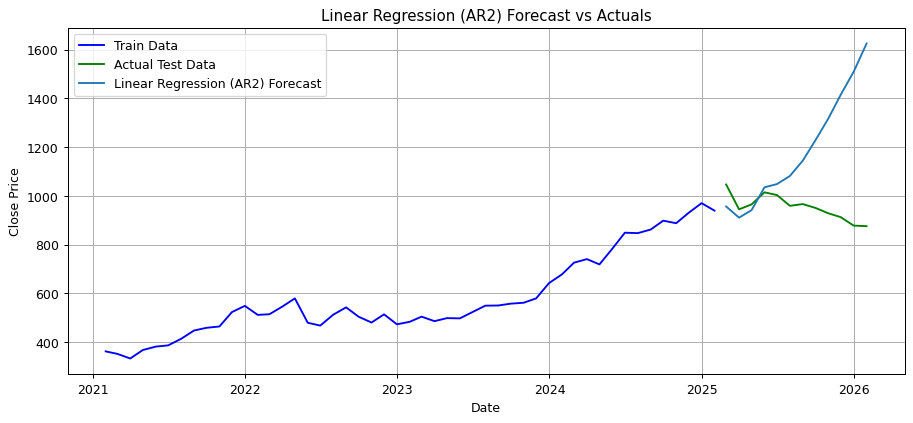

In [504]:
# Plotting AR2 forecast
plt.figure(figsize=(12, 5), dpi = 90)
plt.plot(train_data['Close'], label='Train Data', color='blue')
plt.plot(test_data['Close'], label='Actual Test Data', color='green')
plt.plot(metrics_and_forecast['forecast'], label='Linear Regression (AR2) Forecast')
plt.title('Linear Regression (AR2) Forecast vs Actuals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [505]:
results_all = pd.concat([sma,results_avg_historical, results_simple_avg, naive1, ses, hl, hlms, hlwd,results_lr,results_best_lr], ignore_index=True) #repectively
results_all.sort_values(by='MAPE')

,Method,RMSE,MAE,MAPE
7,Holt Winter Additive Method,36.42,28.38,3.00
6,Holt Winter Multiplicative Method,41.91,29.55,3.12
5,Holt Linear Method,49.84,38.86,4.11
4,Simple Exponential Smoothing,50.44,40.00,4.17
3,Naive Method,51.50,41.49,4.30
9,Linear Regression (AR2),105.87,81.27,8.80
0,Simple Moving Averages method,118.56,107.75,11.06
8,Linear Regression (AR1),194.08,184.35,19.58
1,Average Historical Method,383.75,374.09,38.90
2,Simple Average Method,377.04,373.78,39.04


In [506]:
# fitting Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predicting the second differenced values for the test
linear_regression_diff2_forecast = lr_model.predict(X_test)

# Creating a Series for the forecasted second differenced with the correct index
linear_regression_diff2_forecast_series = pd.Series(linear_regression_diff2_forecast, index=y_test.index)

In [507]:
last_train_diff1_value = monthly_df['Close_diff1'].loc[train_data.index[-1]]

#first differenced forecast
linear_regression_diff1_forecast = [last_train_diff1_value]

# second derivative forecasts to get first derivative
for i in range(len(linear_regression_diff2_forecast_series)):
    linear_regression_diff1_forecast.append(linear_regression_diff1_forecast[-1] + linear_regression_diff2_forecast_series.iloc[i])

# Removing the initial value
linear_regression_diff1_forecast = linear_regression_diff1_forecast[1:]

# Creating series for the first differenced forecast
linear_regression_diff1_forecast_series = pd.Series(linear_regression_diff1_forecast, index=y_test.index)

# Now inverse transformation from Close derivative one to original Close
# for this we need the last actual Close value from the training period as starting point
last_train_close_value = train_data['Close'].iloc[-1]

# original close price forecast
linear_regression_forecast_close = [last_train_close_value]

# Accumulating the first derivative forecast to get original Close price forecast
for i in range(len(linear_regression_diff1_forecast_series)):
    linear_regression_forecast_close.append(linear_regression_forecast_close[-1] + linear_regression_diff1_forecast_series.iloc[i])

# Removing initial value
linear_regression_forecast_close = linear_regression_forecast_close[1:]

#  for final LR forecast results creating dataframe
y_hat_lr_p = test_data.copy()
y_hat_lr_p['Linear_Regression_Forecast'] = linear_regression_forecast_close

print("Linear Regression Forecasts for period =12:")
display(y_hat_lr_p.round(2))

Linear Regression Forecasts for period =12:


,Close,Linear_Regression_Forecast
Date,,
2025-02-28,1046.39,927.85
2025-03-31,944.41,873.67
2025-04-30,964.84,880.23
2025-05-31,1014.36,848.58
2025-06-30,1003.06,806.58
2025-07-31,958.91,781.05
2025-08-31,966.12,763.65
2025-09-30,950.49,729.25
2025-10-31,928.37,699.99


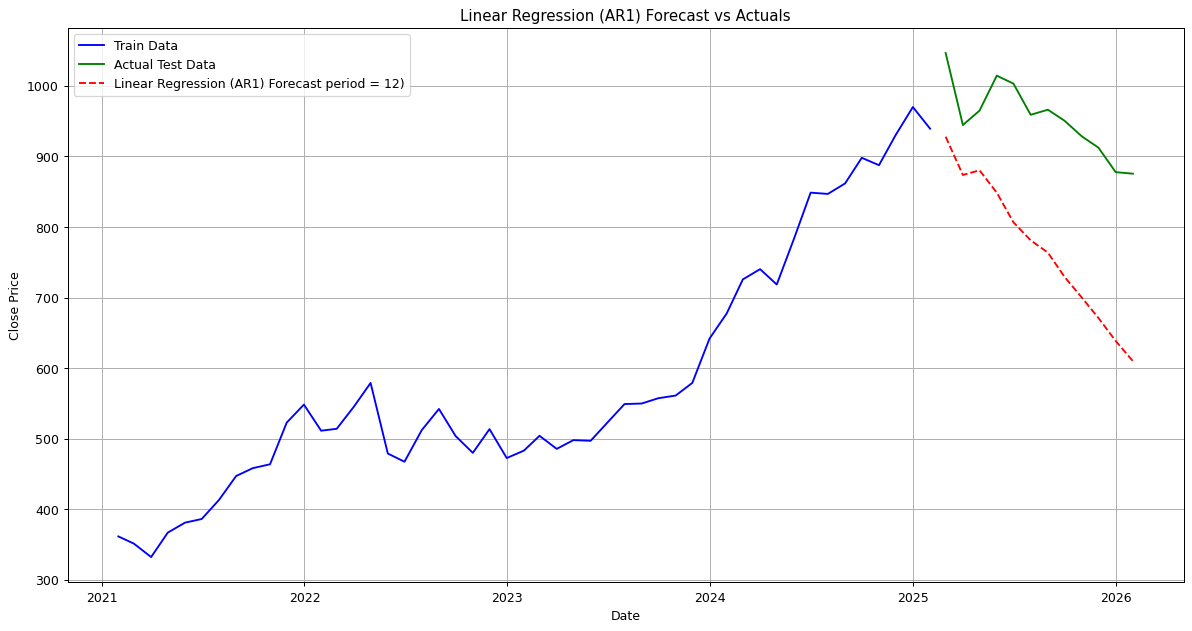

In [508]:
#plotting
plt.figure(figsize=(16, 8),dpi = 90)
plt.plot(train_data['Close'], label='Train Data', color='blue')
plt.plot(test_data['Close'], label='Actual Test Data', color='green')
plt.plot(y_hat_lr_p['Linear_Regression_Forecast'], label='Linear Regression (AR1) Forecast period = 12)', color='red', linestyle='--')
plt.title('Linear Regression (AR1) Forecast vs Actuals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

## Accuracy Metrics

In [509]:
# Accuracy Metrics of all the methods
results_all = pd.concat([results_avg_historical,results_simple_avg,naive1,ses,hl,hlms,hlwd,results_arima,results_sarima,results_lr,results_best_lr], ignore_index=True)

display(results_all.sort_values(by='MAPE'))

,Method,RMSE,MAE,MAPE
6,Holt Winter Additive Method,36.42,28.38,3.00
5,Holt Winter Multiplicative Method,41.91,29.55,3.12
4,Holt Linear Method,49.84,38.86,4.11
3,Simple Exponential Smoothing,50.44,40.00,4.17
2,Naive Method,51.50,41.49,4.30
10,Linear Regression (AR2),105.87,81.27,8.80
8,"SARIMA(2, 2, 2)(1, 1, 1, 12)",127.34,108.93,11.75
7,"ARIMA(2, 2, 1)",152.99,125.58,13.61
9,Linear Regression (AR1),194.08,184.35,19.58
0,Average Historical Method,383.75,374.09,38.90


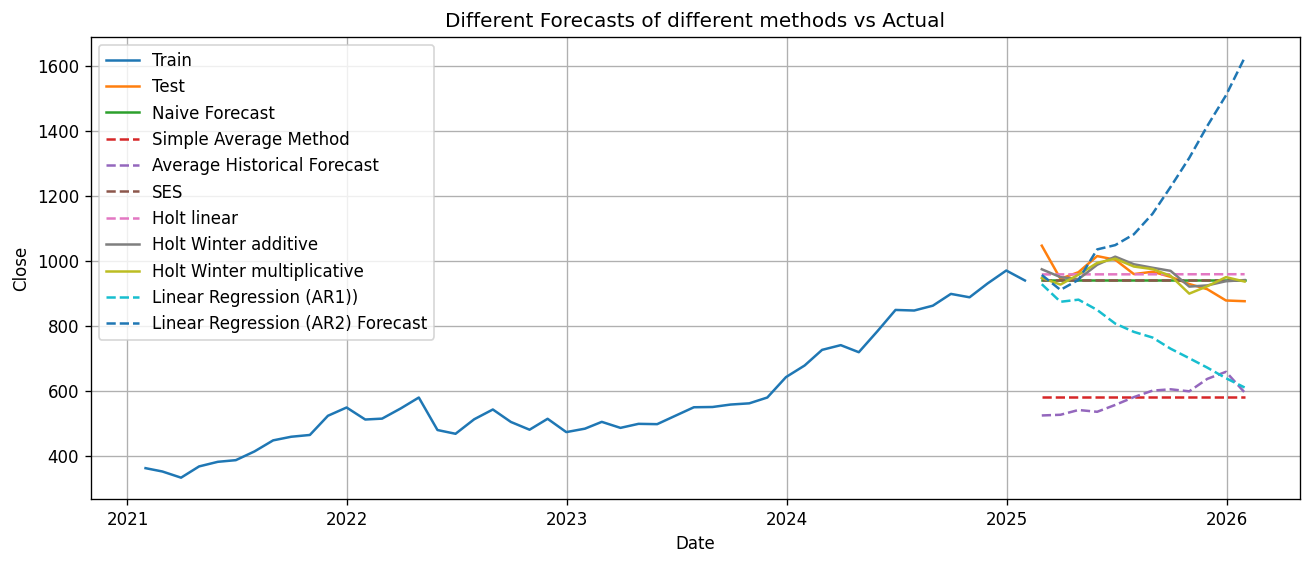

In [510]:
# Plotting all graph of all the previously done methods in one graph
plt.figure(figsize=(13,5), dpi = 120)
plt.plot(train_data['Close'], label='Train')
plt.plot(test_data['Close'], label='Test')
plt.plot(naive_forecast, label='Naive Forecast')
plt.plot(y_hat_simple_avg['simple_average_forecast'], label='Simple Average Method', linestyle = "--")
plt.plot(y_hat_avg_hist['average_historical_forecast'], label='Average Historical Forecast', linestyle = "--")
plt.plot(y_hat_avg['SES'], label='SES', linestyle = "--")
plt.plot(y_hat_avg['Holt_linear'], label='Holt linear', linestyle = "--")
plt.plot(y_hat_add_cr['Holt_Winter'], label='Holt Winter additive')
plt.plot(y_hat_mul_cr['Holt_Winter'], label='Holt Winter multiplicative')
plt.plot(y_hat_lr_p['Linear_Regression_Forecast'], label='Linear Regression (AR1))', linestyle = "--")
plt.plot(metrics_and_forecast['forecast'], label='Linear Regression (AR2) Forecast', linestyle ='--')
plt.title('Different Forecasts of different methods vs Actual')
plt.xlabel('Date')
plt.ylabel('Close')
plt.legend(loc='best')
plt.grid()
plt.show()